# **DATA UNDERSTANDING NOTEBOOK**

In [341]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math


## 1. DATASET LOADING

In [342]:
train_df = pd.read_csv("../data/application_train.csv")
columns_description_df = pd.read_csv("../data/HomeCredit_columns_description.csv", encoding="latin1")

## 2. DATASET INVENTORY

In [343]:
inventory_data = {
    "Dataset": ["application_train", "columns_description"], 
    "Rows": [train_df.shape[0], columns_description_df.shape[0]],
    "Columns": [train_df.shape[1], columns_description_df.shape[1]],
    "Purpose": ["Main application dataset", "Data dictionary"],
    "Main Key": [train_df.columns[0], "-"],
    "Target": [train_df.columns[1], "-"],
}
inventory = pd.DataFrame(data=inventory_data)

In [344]:
inventory

,Dataset,Rows,Columns,Purpose,Main Key,Target
0,application_train,307511,122,Main application dataset,SK_ID_CURR,TARGET
1,columns_description,219,5,Data dictionary,-,-


In [345]:
inventory.to_csv("../outputs/data_understanding/dataset_inventory.csv")

## 3. APPLICATION TRAIN OVERVIEW

In [346]:
train_df

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [347]:
train_df.shape

(307511, 122)

In [348]:
data_types = pd.DataFrame({
    "Feature": train_df.columns,
    "Pandas Type": [
        (
            "Integer"
            if pd.api.types.is_integer_dtype(train_df[col])
            else "Float"
            if pd.api.types.is_float_dtype(train_df[col])
            else "Categorical"
            if train_df[col].dtype == "object"
            else str(train_df[col].dtype)
        )
        for col in train_df.columns
    ]
})
data_types

,Feature,Pandas Type
0,SK_ID_CURR,Integer
1,TARGET,Integer
2,NAME_CONTRACT_TYPE,str
3,CODE_GENDER,str
4,FLAG_OWN_CAR,str
...,...,...
117,AMT_REQ_CREDIT_BUREAU_DAY,Float
118,AMT_REQ_CREDIT_BUREAU_WEEK,Float
119,AMT_REQ_CREDIT_BUREAU_MON,Float
120,AMT_REQ_CREDIT_BUREAU_QRT,Float


In [349]:
identifier_features = [
    "SK_ID_CURR"
]

target_features = [
    "TARGET"
]

external_score_features = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

temporal_features = [
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "DAYS_REGISTRATION",
    "DAYS_ID_PUBLISH",
    "OWN_CAR_AGE",
    "DAYS_LAST_PHONE_CHANGE"
]

ordinal_features = [
    "NAME_EDUCATION_TYPE",
    "REGION_RATING_CLIENT",
    "REGION_RATING_CLIENT_W_CITY"
]

count_features = [
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "OBS_30_CNT_SOCIAL_CIRCLE",
    "DEF_30_CNT_SOCIAL_CIRCLE",
    "OBS_60_CNT_SOCIAL_CIRCLE",
    "DEF_60_CNT_SOCIAL_CIRCLE",
    "AMT_REQ_CREDIT_BUREAU_HOUR",
    "AMT_REQ_CREDIT_BUREAU_DAY",
    "AMT_REQ_CREDIT_BUREAU_WEEK",
    "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT",
    "AMT_REQ_CREDIT_BUREAU_YEAR"
]

In [350]:
binary_features = [
    col
    for col in train_df.columns
    if train_df[col].nunique(dropna=True) == 2
    and col != "TARGET"
]

In [351]:
def get_analytical_type(feature):
    if feature in identifier_features:
        return "Identifier"
    if feature in target_features:
        return "Target"
    if feature in external_score_features:
        return "External Score"
    if feature in temporal_features:
        return "Temporal / Days"
    if feature in ordinal_features:
        return "Ordinal"
    if feature in count_features:
        return "Numerical Count"
    if feature in binary_features:
        return "Binary / Flag"
    if pd.api.types.is_string_dtype(train_df[feature]):
        return "Categorical"
    return "Numerical Continuous"

data_types["Analytical Type"] = data_types["Feature"].apply(get_analytical_type)

In [352]:
data_types

,Feature,Pandas Type,Analytical Type
0,SK_ID_CURR,Integer,Identifier
1,TARGET,Integer,Target
2,NAME_CONTRACT_TYPE,str,Binary / Flag
3,CODE_GENDER,str,Categorical
4,FLAG_OWN_CAR,str,Binary / Flag
...,...,...,...
117,AMT_REQ_CREDIT_BUREAU_DAY,Float,Numerical Count
118,AMT_REQ_CREDIT_BUREAU_WEEK,Float,Numerical Count
119,AMT_REQ_CREDIT_BUREAU_MON,Float,Numerical Count
120,AMT_REQ_CREDIT_BUREAU_QRT,Float,Numerical Count


In [353]:
data_types.to_csv("../outputs/data_understanding/data_types.csv")

In [354]:
general_table = {}
for i in train_df.columns:
    data_column = {
        "dtype": train_df[i].dtype,
        "unique values": train_df[i].unique(),
        "Missing %": round(train_df[i].isnull().mean()*100, 2),
    }
    general_table[i] = data_column

table = pd.DataFrame(data=general_table)
table

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
dtype,int64,int64,str,str,str,str,int64,float64,float64,float64,...,int64,int64,int64,int64,float64,float64,float64,float64,float64,float64
unique values,"[100002, 100003, 100004, 100006, 100007, 10000...","[1, 0]","[Cash loans, Revolving loans]","[M, F, XNA]","[N, Y]","[Y, N]","[0, 1, 2, 3, 4, 7, 5, 6, 8, 9, 11, 12, 10, 19,...","[202500.0, 270000.0, 67500.0, 135000.0, 121500...","[406597.5, 1293502.5, 135000.0, 312682.5, 5130...","[24700.5, 35698.5, 6750.0, 29686.5, 21865.5, 2...",...,"[0, 1]","[0, 1]","[0, 1]","[0, 1]","[0.0, nan, 1.0, 2.0, 3.0, 4.0]","[0.0, nan, 1.0, 3.0, 2.0, 4.0, 5.0, 6.0, 9.0, ...","[0.0, nan, 1.0, 3.0, 2.0, 4.0, 5.0, 6.0, 8.0, ...","[0.0, nan, 1.0, 2.0, 6.0, 5.0, 3.0, 7.0, 9.0, ...","[0.0, nan, 1.0, 2.0, 4.0, 3.0, 8.0, 5.0, 6.0, ...","[1.0, 0.0, nan, 2.0, 4.0, 5.0, 3.0, 8.0, 6.0, ..."
Missing %,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,13.5,13.5,13.5,13.5,13.5,13.5


In [355]:
#Comprobar los valores únicos de IDs
train_df["SK_ID_CURR"].is_unique

True

## 4. DATA DICTIONARY

In [356]:
train_df.columns

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY',
       ...
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='str', length=122)

In [357]:
columns_description_df

,Unnamed: 0,Table,Row,Description,Special
0,1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
1,2,application_{train|test}.csv,TARGET,Target variable (1 - client with payment diffi...,NaN
2,5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
4,7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN
...,...,...,...,...,...
214,217,installments_payments.csv,NUM_INSTALMENT_NUMBER,On which installment we observe payment,NaN
215,218,installments_payments.csv,DAYS_INSTALMENT,When the installment of previous credit was su...,time only relative to the application
216,219,installments_payments.csv,DAYS_ENTRY_PAYMENT,When was the installments of previous credit p...,time only relative to the application
217,220,installments_payments.csv,AMT_INSTALMENT,What was the prescribed installment amount of ...,NaN


In [358]:
general_app_data = {}

for i in range(1, len(columns_description_df)):
    if columns_description_df["Table"][i] == "application_{train|test}.csv":
        app_data_row = {
            "Description": columns_description_df["Description"][i],
            "Data Type": train_df[columns_description_df["Row"][i]].dtype
        }
        general_app_data[columns_description_df["Row"][i]] = app_data_row


application_data = pd.DataFrame(data=general_app_data)
application_data

,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
Description,Target variable (1 - client with payment diffi...,Identification if loan is cash or revolving,Gender of the client,Flag if the client owns a car,Flag if client owns a house or flat,Number of children the client has,Income of the client,Credit amount of the loan,Loan annuity,For consumer loans it is the price of the good...,...,Did client provide document 18,Did client provide document 19,Did client provide document 20,Did client provide document 21,Number of enquiries to Credit Bureau about the...,Number of enquiries to Credit Bureau about the...,Number of enquiries to Credit Bureau about the...,Number of enquiries to Credit Bureau about the...,Number of enquiries to Credit Bureau about the...,Number of enquiries to Credit Bureau about the...
Data Type,int64,str,str,str,str,int64,float64,float64,float64,float64,...,int64,int64,int64,int64,float64,float64,float64,float64,float64,float64


## 5. VARIABLE TYPES

## 6. TARGET ANALYSIS

In [359]:
target_one_values = train_df["TARGET"][train_df["TARGET"] == 1].count()
target_one_values

np.int64(24825)

In [360]:
target_cero_values = train_df["TARGET"][train_df["TARGET"] == 0].count()
target_cero_values

np.int64(282686)

In [361]:
total_target_values = (train_df["TARGET"].shape)[0]

percentage_one_target = (target_one_values / total_target_values) * 100
percentage_cero_target = (target_cero_values / total_target_values) * 100

print(f"The {round(percentage_one_target, 2)}% of the TARGET values are 1")
print(f"The {round(percentage_cero_target, 2)}% of the TARGET values are 0")

The 8.07% of the TARGET values are 1
The 91.93% of the TARGET values are 0


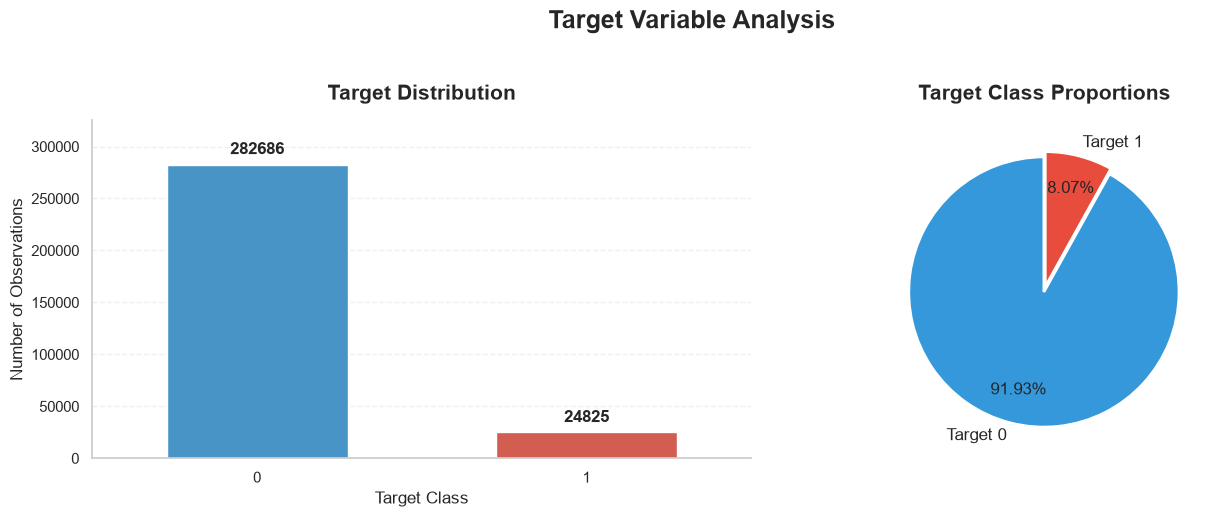

In [362]:
sns.set_theme(style='whitegrid')

colors = ["#3498db", "#e74c3c"]
labels = ["Target 0", "Target 1"]
counts = [target_cero_values, target_one_values]
percentages = [percentage_cero_target, percentage_one_target]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    x=["0", "1"],
    y=counts,
    hue=["0", "1"],
    palette=colors,
    legend=False,
    width=0.55,
    ax=axes[0]
)

for container in axes[0].containers:
    axes[0].bar_label(
        container,
        fmt="%d",
        padding=5,
        fontsize=12,
        fontweight="bold"
    )

axes[0].set_title("Target Distribution", fontsize=15, fontweight="bold", pad=15)
axes[0].set_xlabel("Target Class", fontsize=12)
axes[0].set_ylabel("Number of Observations", fontsize=12)
axes[0].set_ylim(0, max(counts) * 1.15)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)
axes[0].grid(axis="x", visible=False)

sns.despine(ax=axes[0])

axes[1].pie(
    percentages,
    labels=labels,
    autopct="%1.2f%%",
    colors=colors,
    startangle=90,
    explode=(0.02, 0.02),
    pctdistance=0.75,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 12}
)

axes[1].set_title("Target Class Proportions", fontsize=15, fontweight="bold", pad=15)

fig.suptitle(
    "Target Variable Analysis",
    fontsize=18,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()
plt.savefig(
    "../outputs/figures/target_distribution.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

## 7. MISSING VALUES

In [363]:
train_df

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
missing_values_general = {}

for i in train_df:
    count_null_values = train_df[i].isnull().sum()
    count_total_values = train_df[i].shape[0]
    null_percentage = (count_null_values / count_total_values) * 100
    missing_values_general[i] = {
        "Missing Count": count_null_values,
        "Missing Percentage": null_percentage
    }

missing_values_per_feature_df = pd.DataFrame(data=missing_values_general)
missing_values_per_feature_df.T

,Missing Count,Missing Percentage
SK_ID_CURR,0.0,0.000000
TARGET,0.0,0.000000
NAME_CONTRACT_TYPE,0.0,0.000000
CODE_GENDER,0.0,0.000000
FLAG_OWN_CAR,0.0,0.000000
...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,41519.0,13.501631
AMT_REQ_CREDIT_BUREAU_WEEK,41519.0,13.501631
AMT_REQ_CREDIT_BUREAU_MON,41519.0,13.501631
AMT_REQ_CREDIT_BUREAU_QRT,41519.0,13.501631


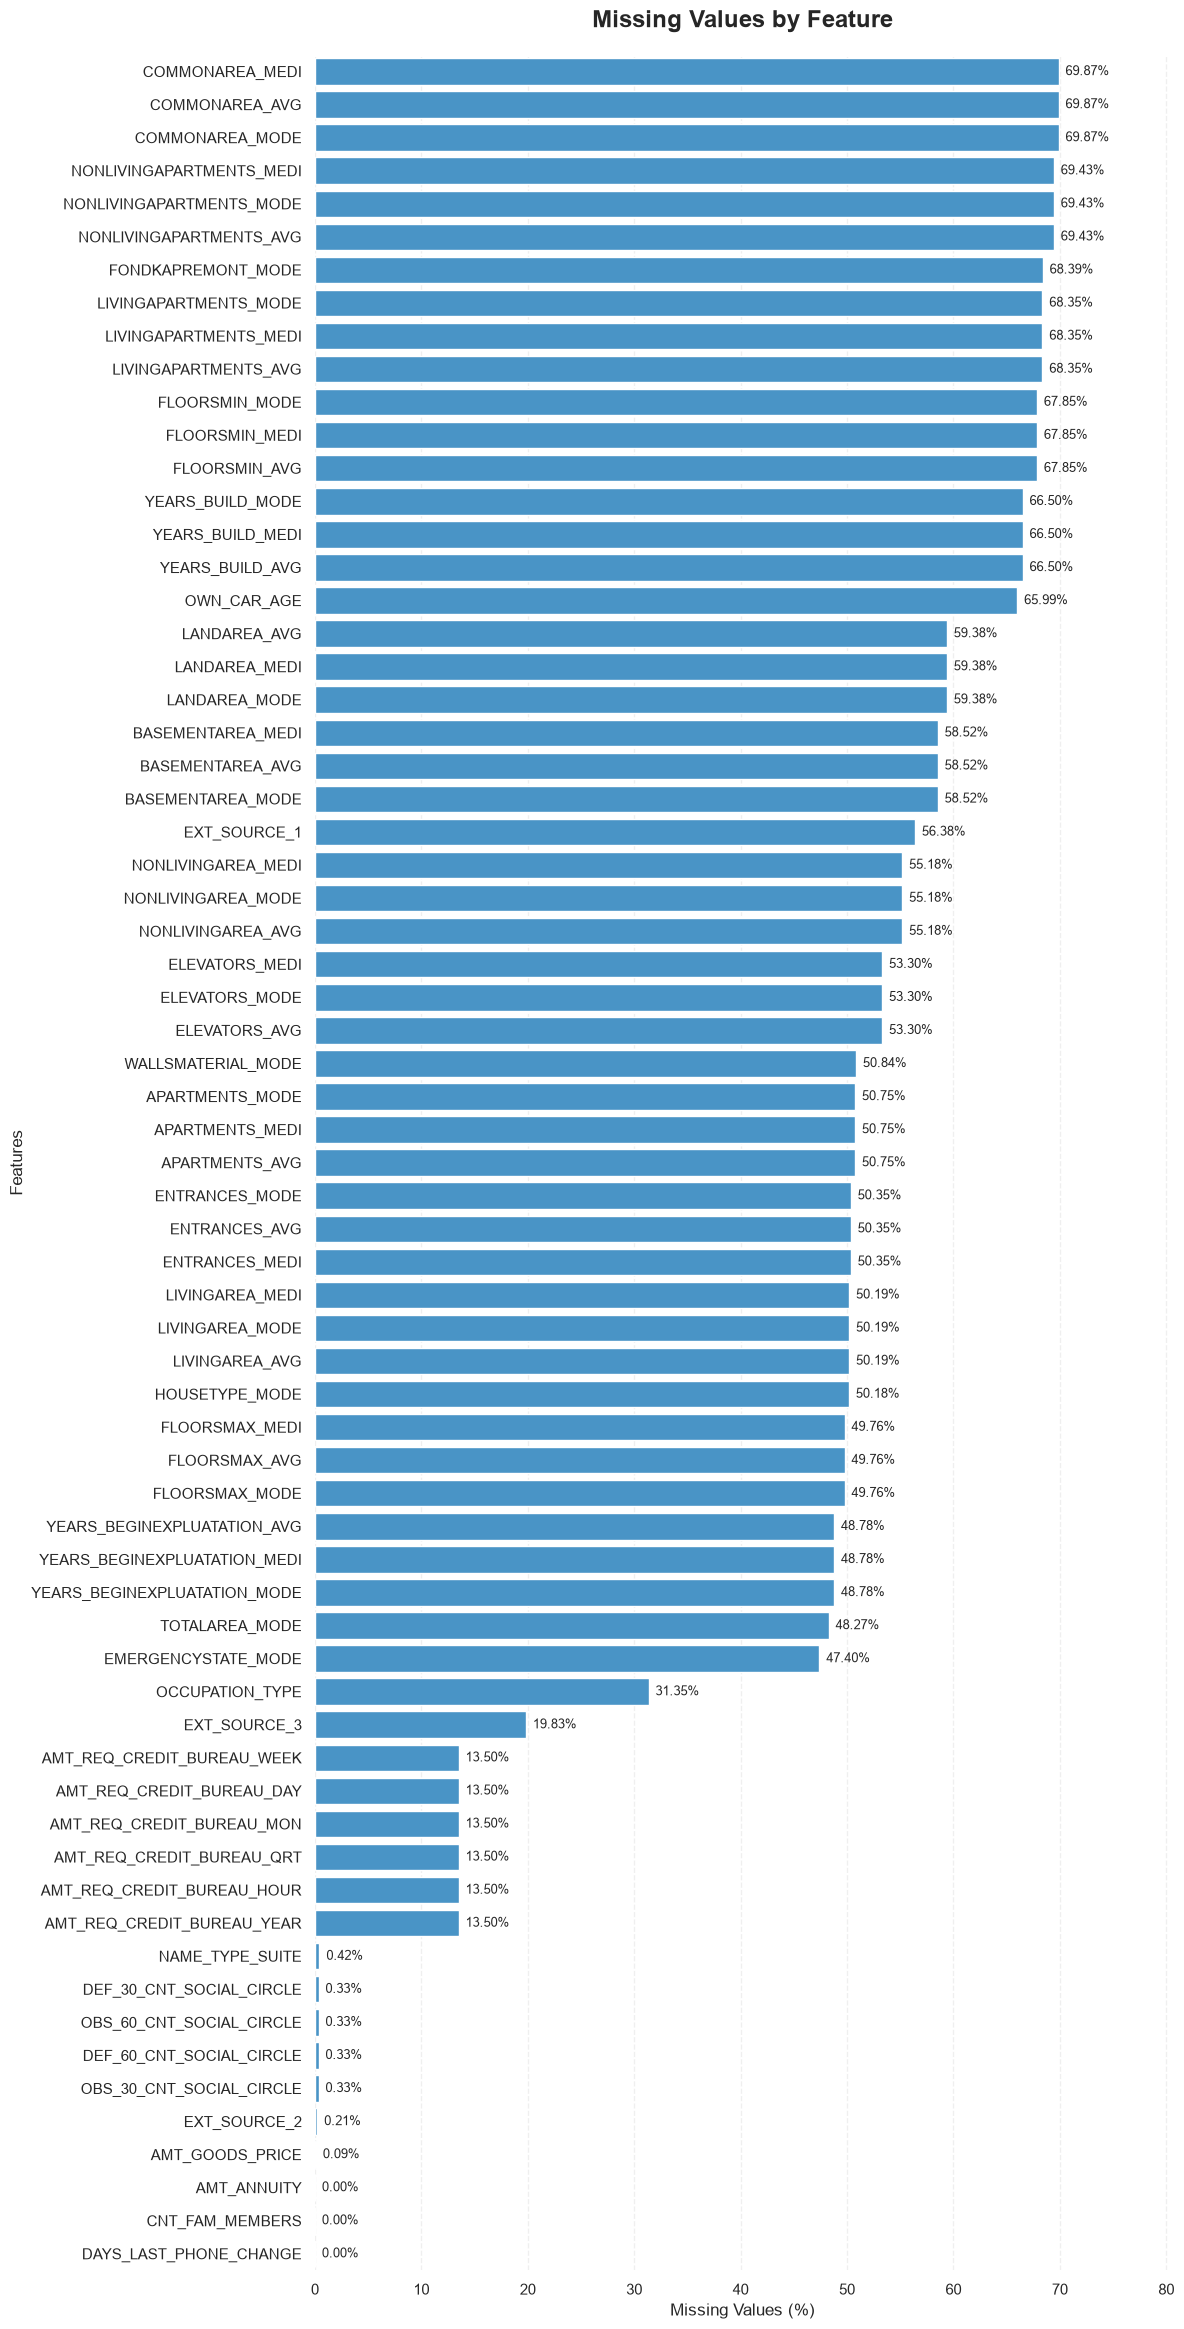

In [365]:
missing_df = missing_values_per_feature_df.T
missing_df = missing_df[missing_df["Missing Count"] > 0]

missing_df = missing_df.sort_values(by="Missing Percentage", ascending=False)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, max(6, len(missing_df) * 0.35)))

sns.barplot(
    data=missing_df,
    x="Missing Percentage",
    y=missing_df.index,
    color="#3498db",
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=5,
        fontsize=9,
    )

ax.set_title(
    "Missing Values by Feature",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Missing Values (%)", fontsize=12)
ax.set_ylabel("Features", fontsize=12)
ax.set_xlim(0, max(missing_df["Missing Percentage"].max() * 1.15, 1))
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.grid(axis="y", visible=False)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.savefig(
    "../outputs/figures/missing_values_target.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()


## 8. DUPLICATE AND ID CHECKS

In [366]:
train_df

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [367]:
#Comprobar si hay valores duplicados en la columna SK_ID_CURR

train_df["SK_ID_CURR"].is_unique

True

In [368]:
train_df.shape

(307511, 122)

In [369]:
#Comprobar que no haya filas duplicadas, es decir, que cada fila sea única.

df_train_unique = train_df.drop_duplicates()
df_train_unique.shape

(307511, 122)

## 9. NUMERICAL VARIABLES

In [370]:
#Resumen estadístico del dataset
statistics_train_dataset = train_df.describe()
statistics_train_dataset.to_csv("../outputs/data_understanding/numerical_summary.csv")
statistics_train_dataset


,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [371]:
#Buscar anomalías
numerical_features = data_types.loc[
    data_types["Analytical Type"].isin([
        "Numerical Continuous",
        "Numerical Count",
        "Temporal / Days",
        "External Score"
    ]),
    "Feature"
].tolist()
numerical_df = train_df[numerical_features]
numerical_summary = numerical_df.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
numerical_summary

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.00,0.0,0.0,0.0,1.0,2.0,3.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,45000.00,67500.0,112500.0,147150.0,202500.0,337500.0,472500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,76410.00,135000.0,270000.0,513531.0,808650.0,1350000.0,1854000.0,4050000.0
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1615.5,6182.91,9000.0,16524.0,24903.0,34596.0,53325.0,70006.5,258025.5
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,40500.0,67500.00,135000.0,238500.0,450000.0,679500.0,1305000.0,1800000.0,4050000.0
...,...,...,...,...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.00,0.0,0.0,0.0,0.0,0.0,1.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.00,0.0,0.0,0.0,0.0,1.0,4.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.00,0.0,0.0,0.0,0.0,2.0,2.0,261.0


In [372]:
#Buscar anomalias en fechas de nacimiento

age_years = -train_df["DAYS_BIRTH"] / 365.25
age_years.describe()

count    307511.000000
mean         43.906900
std          11.947950
min          20.503765
25%          33.984942
50%          43.121150
75%          53.886379
max          69.073238
Name: DAYS_BIRTH, dtype: float64

In [373]:
train_df["DAYS_EMPLOYED"].value_counts()

DAYS_EMPLOYED
 365243    55374
-200         156
-224         152
-199         151
-230         151
           ...  
-12316         1
-11100         1
-12971         1
-11084         1
-8694          1
Name: count, Length: 12574, dtype: int64

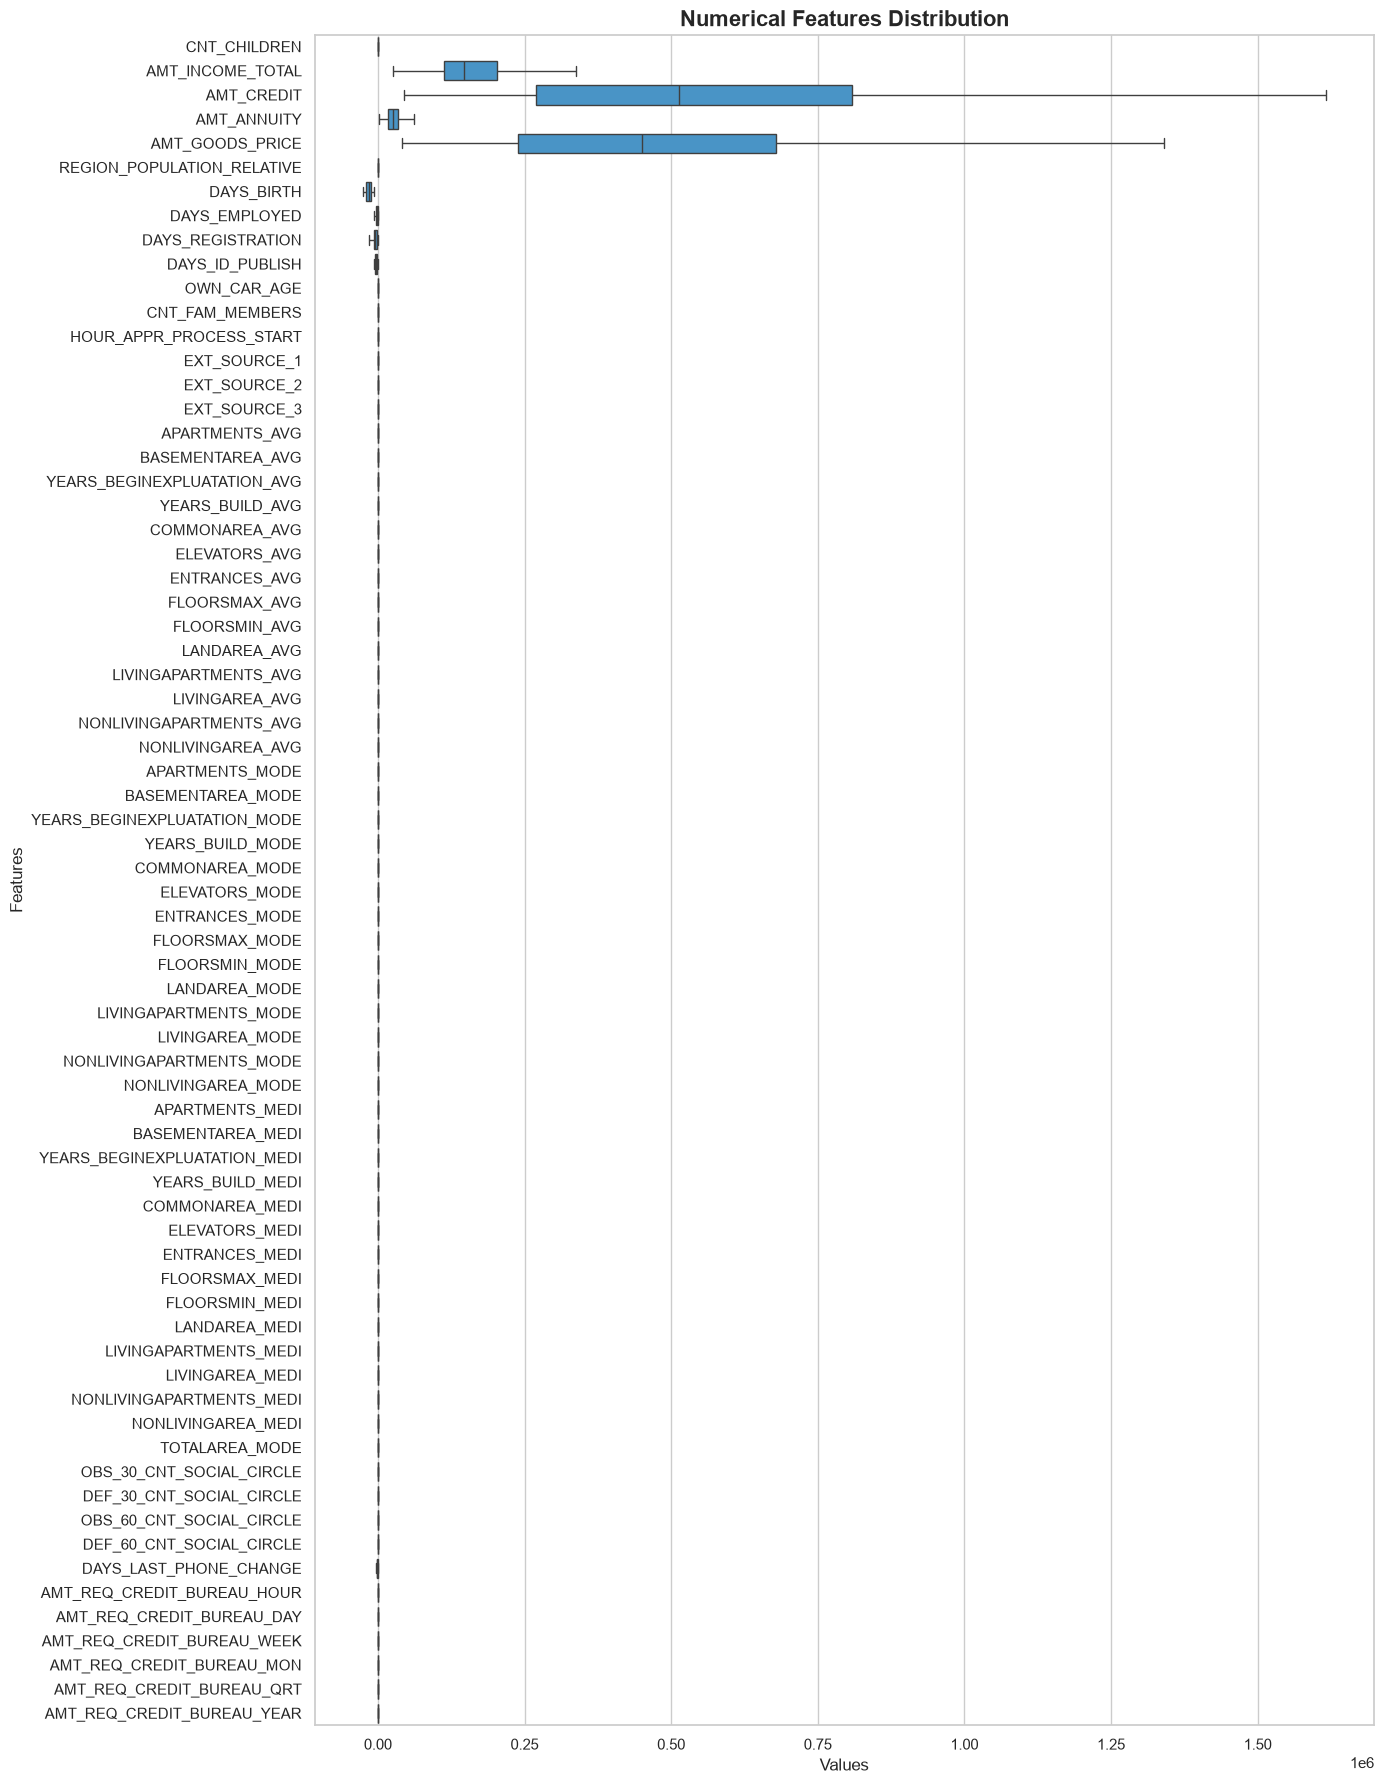

In [374]:
#Se visualiza mal, por ello en la siguiente se estandarizan los datos para un rango comun, pero este es el más bruto
fig, ax = plt.subplots(figsize=(14, 18))

sns.boxplot(
    data=numerical_df,
    orient="h",
    showfliers=False,
    color="#3498db",
    ax=ax
)

ax.set_title("Numerical Features Distribution", fontsize=16, fontweight="bold")
ax.set_xlabel("Values")
ax.set_ylabel("Features")

plt.tight_layout()
plt.show()

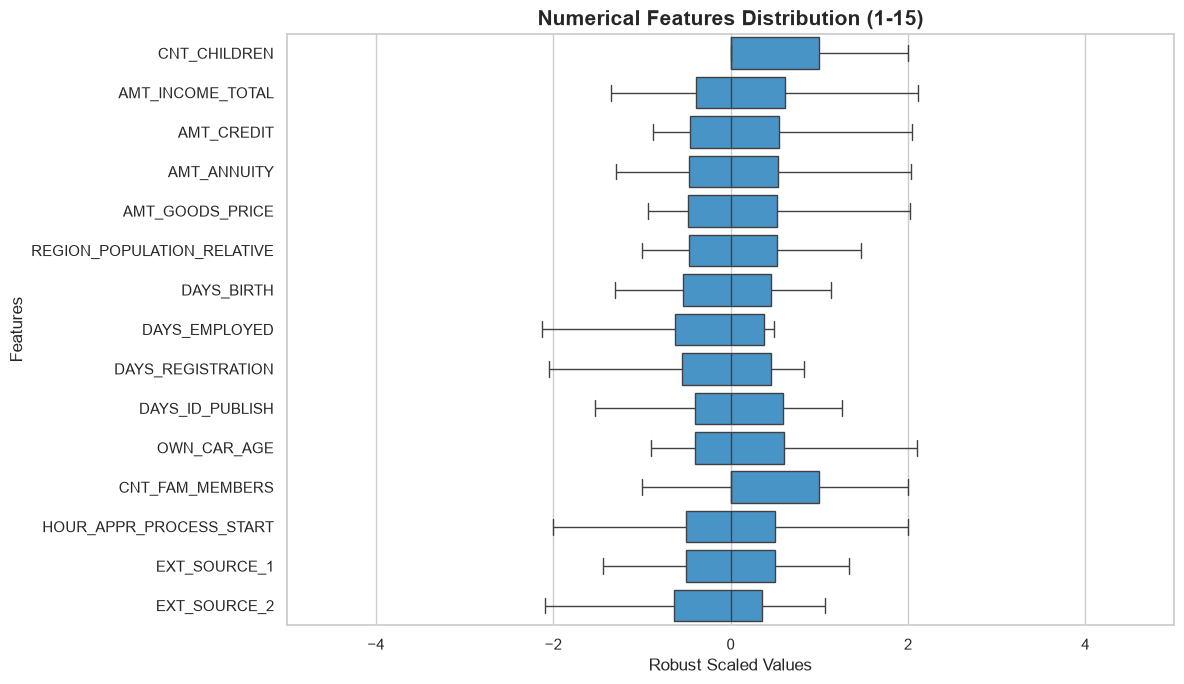

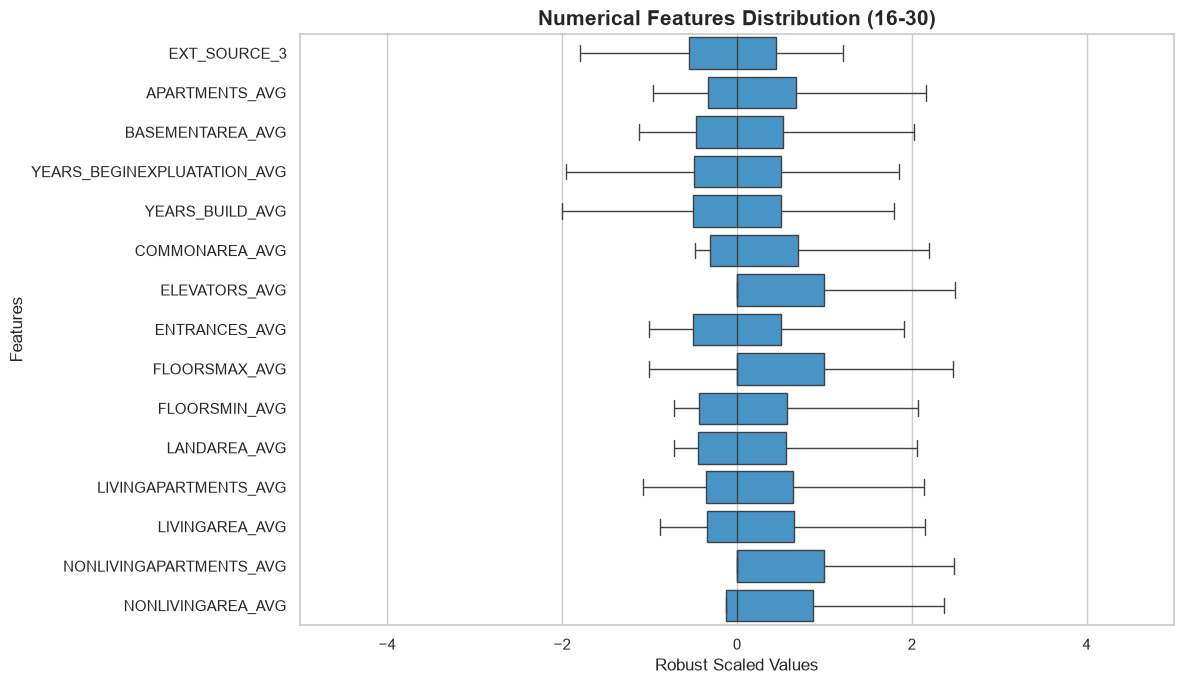

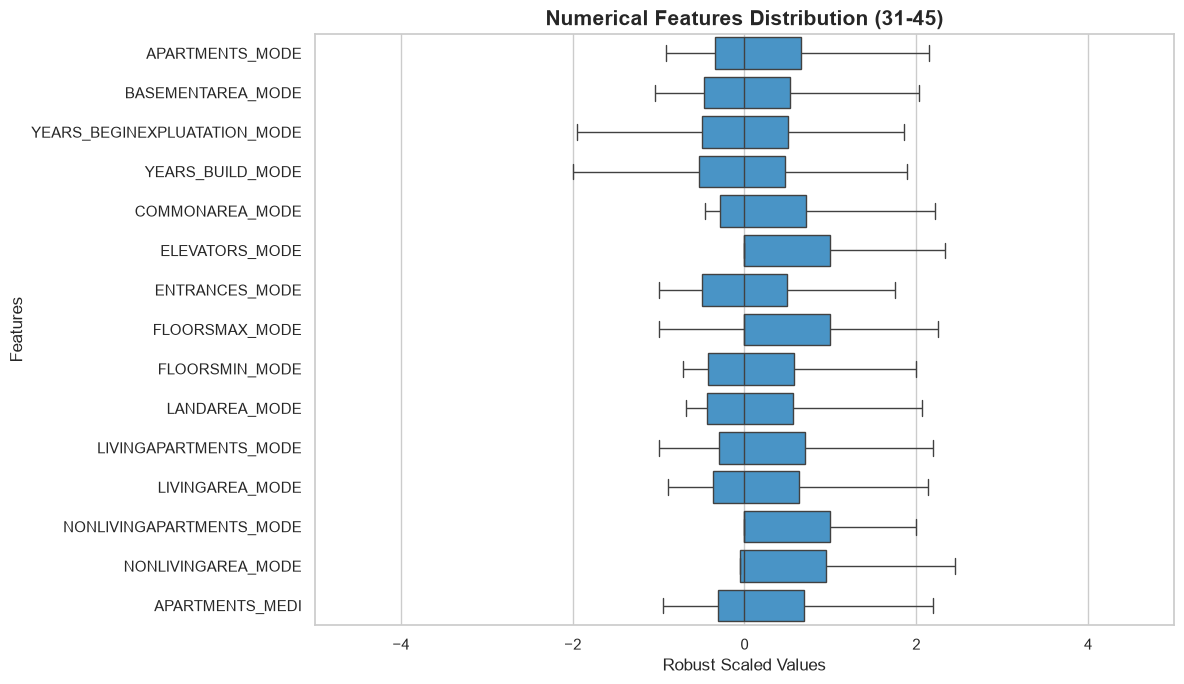

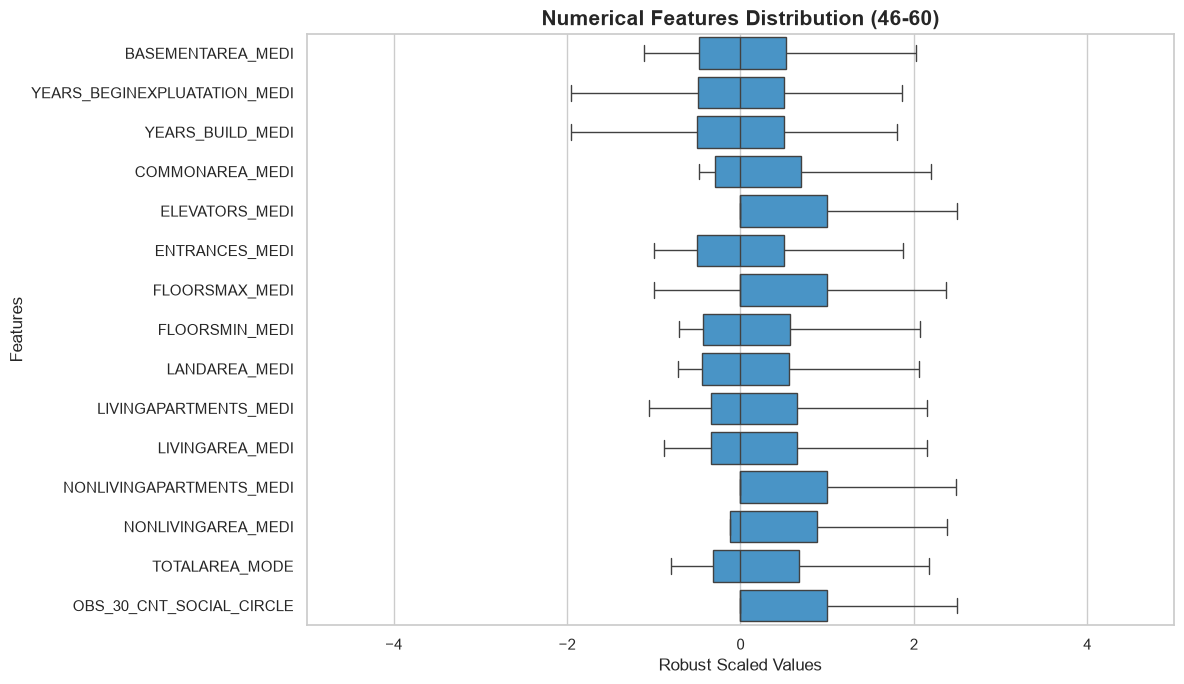

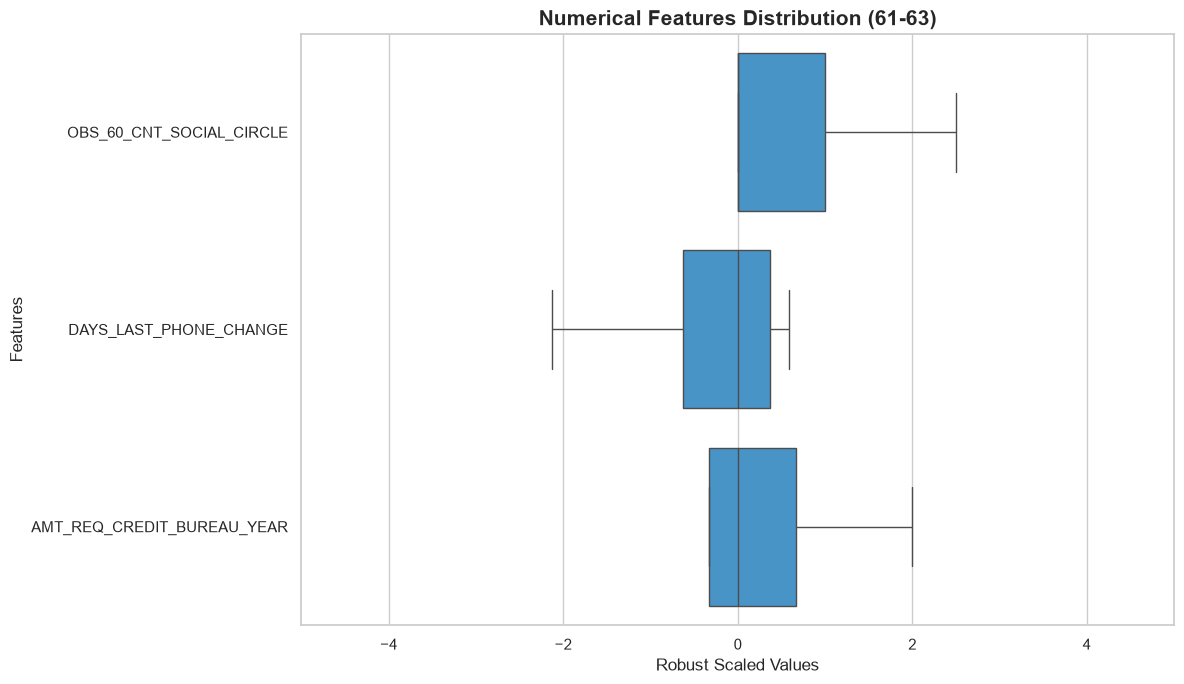

In [375]:
sns.set_theme(style="whitegrid")

# 1. NUMERICAL FEATURES - BOXPLOT

features = numerical_df.apply(pd.to_numeric, errors="coerce")

features = features.loc[:, features.nunique() > 2]

q1 = features.quantile(0.25)
q3 = features.quantile(0.75)
iqr = q3 - q1

features = features.loc[:, iqr > 0]

scaled_features = (
    features - features.median()
) / iqr[iqr > 0]

for start in range(0, scaled_features.shape[1], 15):
    subset = scaled_features.iloc[:, start:start + 15]
    fig, ax = plt.subplots(figsize=(12, 7))
    sns.boxplot(
        data=subset,
        orient="h",
        showfliers=False,
        color="#3498db",
        ax=ax
    )
    ax.set_xlim(-5, 5)
    ax.set_title(
        f"Numerical Features Distribution ({start + 1}-{start + len(subset.columns)})",
        fontsize=15,
        fontweight="bold"
    )
    ax.set_xlabel("Robust Scaled Values")
    ax.set_ylabel("Features")

    plt.tight_layout()
    plt.show()

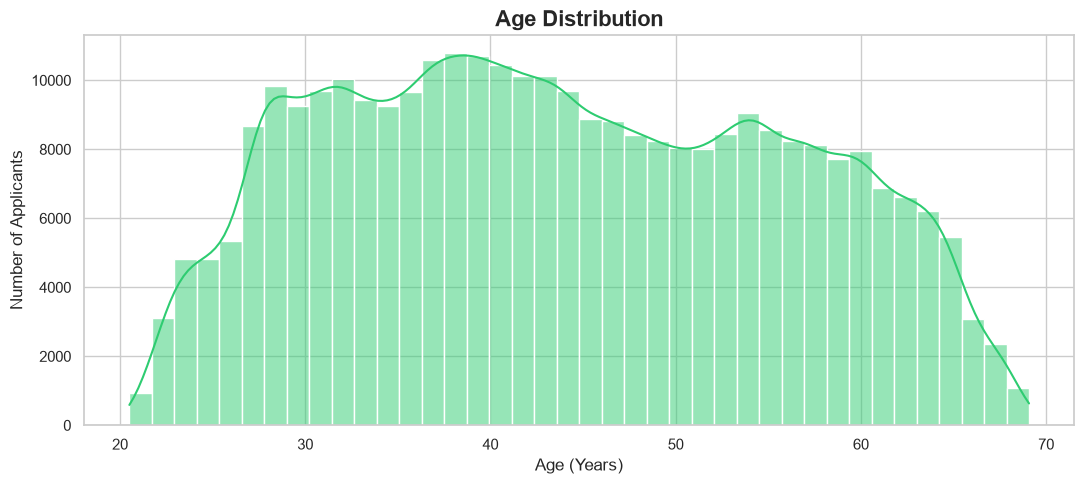

In [376]:
# Visualización de la distribución de edad en DAYS_BIRTH
# 2. DAYS_BIRTH - HISTOGRAM
fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(
    x=age_years,
    bins=40,
    kde=True,
    color="#2ecc71",
    edgecolor="white",
    ax=ax
)
ax.set_title("Age Distribution", fontsize=16, fontweight="bold")
ax.set_xlabel("Age (Years)")
ax.set_ylabel("Number of Applicants")

plt.tight_layout()
plt.show()

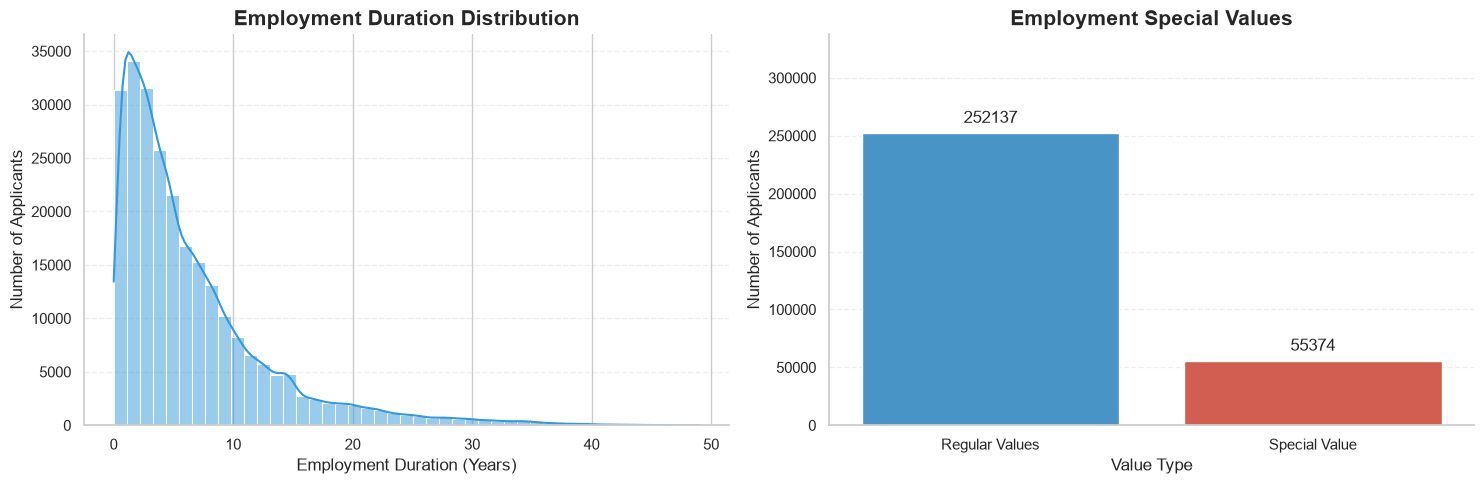

In [377]:
# Distribución de los años de empleado que tienen los solicitantes
# 3. DAYS_EMPLOYED - BAR CHART

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    x=-train_df.loc[
        train_df["DAYS_EMPLOYED"] != 365243,
        "DAYS_EMPLOYED"
    ] / 365.25,
    bins=45,
    kde=True,
    color="#3498db",
    edgecolor="white",
    ax=axes[0]
)
axes[0].set_title("Employment Duration Distribution", fontsize=15, fontweight="bold")
axes[0].set_xlabel("Employment Duration (Years)")
axes[0].set_ylabel("Number of Applicants")
sns.countplot(
    x=train_df["DAYS_EMPLOYED"].eq(365243).map({
        False: "Regular Values",
        True: "Special Value"
    }),
    order=["Regular Values", "Special Value"],
    hue=train_df["DAYS_EMPLOYED"].eq(365243).map({
        False: "Regular Values",
        True: "Special Value"
    }),
    palette=["#3498db", "#e74c3c"],
    legend=False,
    ax=axes[1]
)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%d", padding=5)
axes[1].set_title(
    "Employment Special Values",
    fontsize=15,
    fontweight="bold"
)
axes[1].set_xlabel("Value Type")
axes[1].set_ylabel("Number of Applicants")
axes[1].set_ylim(0, len(train_df) * 1.1)
for ax in axes:
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()

## 10. CATEGORICAL VARIABLES

In [378]:
#Categorical analysis
categorical_features = data_types.loc[
    data_types["Analytical Type"].isin([
        "Categorical",
        "Ordinal",
        "Binary / Flag"
    ]),
    "Feature"
].tolist()
categorical_df = train_df[categorical_features]
categorical_df

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,FLAG_MOBIL,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
0,Cash loans,M,N,Y,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0
1,Cash loans,F,N,N,Family,State servant,Higher education,Married,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0
2,Revolving loans,M,Y,Y,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0
3,Cash loans,F,N,Y,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0
4,Cash loans,M,N,Y,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,Cash loans,M,N,N,Unaccompanied,Working,Secondary / secondary special,Separated,With parents,1,...,0,0,0,0,0,0,0,0,0,0
307507,Cash loans,F,N,Y,Unaccompanied,Pensioner,Secondary / secondary special,Widow,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0
307508,Cash loans,F,N,Y,Unaccompanied,Working,Higher education,Separated,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0
307509,Cash loans,F,N,Y,Unaccompanied,Commercial associate,Secondary / secondary special,Married,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0


In [379]:
categorical_analysis = {}
index = 1
for i in categorical_df.columns:
    data_feature = {
        "Feature": i,
        "Unique Categories": list(categorical_df[i].unique()),
        "Missing %": float(round((categorical_df[i].isnull().sum() / len(categorical_df[i])) * 100, 2)),
        "Most Frequent": categorical_df[i].value_counts().idxmax(),
    }
    categorical_analysis[index] = data_feature
    index += 1

categorical_df_analitical = pd.DataFrame(data=categorical_analysis)
categorical_df_analitical.to_csv("../outputs/data_understanding/categorical_cardinality.csv")
categorical_df_analitical

,1,2,3,4,5,6,7,8,9,10,...,41,42,43,44,45,46,47,48,49,50
Feature,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,FLAG_MOBIL,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
Unique Categories,"[Cash loans, Revolving loans]","[M, F, XNA]","[N, Y]","[Y, N]","[Unaccompanied, Family, Spouse, partner, Child...","[Working, State servant, Commercial associate,...","[Secondary / secondary special, Higher educati...","[Single / not married, Married, Civil marriage...","[House / apartment, Rented apartment, With par...","[1, 0]",...,"[0, 1]","[0, 1]","[0, 1]","[0, 1]","[0, 1]","[0, 1]","[0, 1]","[0, 1]","[0, 1]","[0, 1]"
Missing %,0.0,0.0,0.0,0.0,0.42,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Most Frequent,Cash loans,F,N,Y,Unaccompanied,Working,Secondary / secondary special,Married,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0


## 11. ANOMALY DETECTION

In [380]:
#Calcular ratio diferencial entre el máximo y el percentil 99 de cada feature.

anomaly_summary = numerical_summary[["min", "1%", "50%", "99%", "max"]].copy()
anomaly_summary["Max / P99"] = anomaly_summary["max"] / anomaly_summary["99%"].replace(0, float("nan"))
anomaly_summary = anomaly_summary.sort_values(by="Max / P99", ascending=False)

anomaly_summary.head(20)

,min,1%,50%,99%,max,Max / P99
AMT_INCOME_TOTAL,25650.0,45000.00,147150.0000,472500.000000,117000000.0,247.619048
AMT_REQ_CREDIT_BUREAU_QRT,0.0,0.00,0.0000,2.000000,261.0,130.500000
OBS_30_CNT_SOCIAL_CIRCLE,0.0,0.00,0.0000,10.000000,348.0,34.800000
OBS_60_CNT_SOCIAL_CIRCLE,0.0,0.00,0.0000,10.000000,344.0,34.400000
DEF_30_CNT_SOCIAL_CIRCLE,0.0,0.00,0.0000,2.000000,34.0,17.000000
DEF_60_CNT_SOCIAL_CIRCLE,0.0,0.00,0.0000,2.000000,24.0,12.000000
NONLIVINGAPARTMENTS_MODE,0.0,0.00,0.0000,0.097300,1.0,10.277492
NONLIVINGAPARTMENTS_MEDI,0.0,0.00,0.0000,0.104800,1.0,9.541985
NONLIVINGAPARTMENTS_AVG,0.0,0.00,0.0000,0.108100,1.0,9.250694
AMT_REQ_CREDIT_BUREAU_WEEK,0.0,0.00,0.0000,1.000000,8.0,8.000000


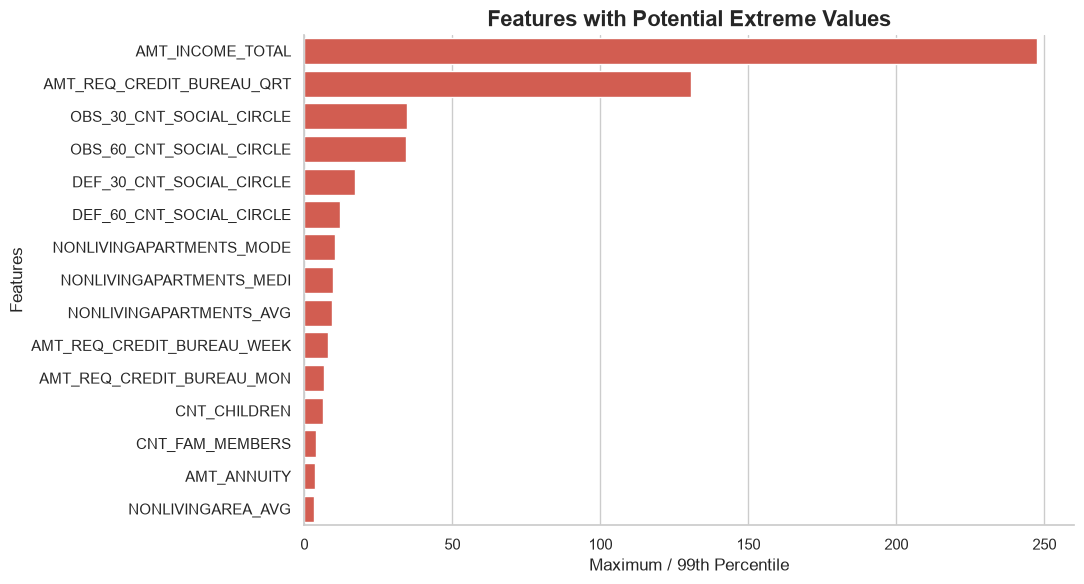

In [381]:
#Mostrar las features con mayor diferencia entre su máximo y su percentil 99 --> Indica posibilidad de outliers fuertes contra mayor sea este valor.
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(
    data=anomaly_summary.head(15),
    x="Max / P99",
    y=anomaly_summary.head(15).index,
    color="#e74c3c",
    ax=ax
)
ax.set_title(
    "Features with Potential Extreme Values",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Maximum / 99th Percentile")
ax.set_ylabel("Features")

sns.despine()
plt.tight_layout()
plt.show()

## 12. RELATIONSHIPS WITH TARGET

The overall payment difficulty rate is approximately 8.07%, which is used as a reference when analysing individual predictors.

Relacion entre las features numéricas y la feature TARGET

In [382]:
numerical_features = data_types.loc[
    data_types["Analytical Type"].isin([
        "Numerical Continuous",
        "Numerical Count",
        "Temporal / Days",
        "External Score"
    ]),
    "Feature"
].tolist()

relationship_df = train_df[numerical_features + ["TARGET"]]
relationship_df

,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,...,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,202500.0,406597.5,24700.5,351000.0,0.018801,-9461,-637,-3648.0,-2120,...,2.0,2.0,-1134.0,0.0,0.0,0.0,0.0,0.0,1.0,1
1,0,270000.0,1293502.5,35698.5,1129500.0,0.003541,-16765,-1188,-1186.0,-291,...,1.0,0.0,-828.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,0,67500.0,135000.0,6750.0,135000.0,0.010032,-19046,-225,-4260.0,-2531,...,0.0,0.0,-815.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,0,135000.0,312682.5,29686.5,297000.0,0.008019,-19005,-3039,-9833.0,-2437,...,2.0,0.0,-617.0,NaN,NaN,NaN,NaN,NaN,NaN,0
4,0,121500.0,513000.0,21865.5,513000.0,0.028663,-19932,-3038,-4311.0,-3458,...,0.0,0.0,-1106.0,0.0,0.0,0.0,0.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,0,157500.0,254700.0,27558.0,225000.0,0.032561,-9327,-236,-8456.0,-1982,...,0.0,0.0,-273.0,NaN,NaN,NaN,NaN,NaN,NaN,0
307507,0,72000.0,269550.0,12001.5,225000.0,0.025164,-20775,365243,-4388.0,-4090,...,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0
307508,0,153000.0,677664.0,29979.0,585000.0,0.005002,-14966,-7921,-6737.0,-5150,...,6.0,0.0,-1909.0,1.0,0.0,0.0,1.0,0.0,1.0,0
307509,0,171000.0,370107.0,20205.0,319500.0,0.005313,-11961,-4786,-2562.0,-931,...,0.0,0.0,-322.0,0.0,0.0,0.0,0.0,0.0,0.0,1


In [383]:
target_0 = relationship_df[relationship_df["TARGET"] == 0]
target_1 = relationship_df[relationship_df["TARGET"] == 1]
print(target_0.shape)
print(target_1.shape)

(282686, 71)
(24825, 71)


In [384]:
statistics_target_0 = target_0.drop(columns="TARGET").describe()
statistics_target_0.to_csv("../outputs/data_understanding/numerical_target_describe_0.csv")
statistics_target_0

,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,...,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,282686.000000,2.826860e+05,2.826860e+05,282674.000000,2.824290e+05,282686.000000,282686.000000,282686.000000,282686.000000,282686.000000,...,281701.000000,281701.000000,281701.000000,282685.000000,245459.000000,245459.000000,245459.000000,245459.000000,245459.000000,245459.000000
mean,0.412946,1.690777e+05,6.026483e+05,27163.623349,5.427368e+05,0.021021,-16138.176397,65696.146123,-5029.941065,-3017.219788,...,0.139148,1.398923,0.096688,-976.388294,0.006380,0.006914,0.034315,0.270697,0.265939,1.889199
std,0.718843,1.104763e+05,4.068459e+05,14658.307178,3.737855e+05,0.013978,4364.200856,142877.810161,3538.464478,1506.614090,...,0.439768,2.381793,0.355771,831.210739,0.083759,0.111091,0.204747,0.928799,0.805355,1.863376
min,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,-24672.000000,-7197.000000,...,0.000000,0.000000,0.000000,-4292.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.125000e+05,2.700000e+05,16456.500000,2.385000e+05,0.010006,-19793.750000,-2813.000000,-7550.000000,-4313.000000,...,0.000000,0.000000,0.000000,-1586.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,1.485000e+05,5.177880e+05,24876.000000,4.500000e+05,0.018850,-15877.000000,-1235.000000,-4544.000000,-3295.000000,...,0.000000,0.000000,0.000000,-776.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,1.000000,2.025000e+05,8.100000e+05,34749.000000,6.885000e+05,0.028663,-12536.000000,-278.000000,-2045.000000,-1755.000000,...,0.000000,2.000000,0.000000,-281.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,19.000000,1.800009e+07,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,0.000000,0.000000,...,34.000000,344.000000,24.000000,0.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [385]:
statistics_target_1 = target_1.drop(columns="TARGET").describe()
statistics_target_1.to_csv("../outputs/data_understanding/numerical_target_describe_1.csv")
statistics_target_1

,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,...,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,24825.000000,2.482500e+04,2.482500e+04,24825.000000,2.480400e+04,24825.000000,24825.000000,24825.000000,24825.000000,24825.000000,...,24789.000000,24789.000000,24789.000000,24825.000000,20533.000000,20533.000000,20533.000000,20533.000000,20533.000000,20533.000000
mean,0.463807,1.656118e+05,5.577785e+05,26481.744290,4.889724e+05,0.019131,-14884.828077,42394.675448,-4487.127009,-2732.099617,...,0.191980,1.477672,0.138247,-808.796818,0.006672,0.008036,0.034919,0.227926,0.259923,2.028783
std,0.756903,7.466770e+05,3.464332e+05,12450.676999,3.116365e+05,0.011905,4192.844583,119484.634253,3299.650241,1516.975313,...,0.516524,2.355908,0.427645,758.090713,0.084926,0.106682,0.203941,0.745116,0.643789,1.934063
min,0.000000,2.565000e+04,4.500000e+04,2722.500000,4.500000e+04,0.000533,-25168.000000,-16069.000000,-22928.000000,-6207.000000,...,0.000000,0.000000,0.000000,-4070.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.125000e+05,2.844000e+05,17361.000000,2.385000e+05,0.009630,-18037.000000,-2156.000000,-6646.000000,-4119.000000,...,0.000000,0.000000,0.000000,-1301.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,0.000000,1.350000e+05,4.975200e+05,25263.000000,4.500000e+05,0.018634,-14282.000000,-1034.000000,-4056.000000,-2797.000000,...,0.000000,0.000000,0.000000,-594.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
75%,1.000000,2.025000e+05,7.333155e+05,32976.000000,6.750000e+05,0.025164,-11396.000000,-379.000000,-1671.000000,-1392.000000,...,0.000000,2.000000,0.000000,-194.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,11.000000,1.170000e+08,4.027680e+06,149211.000000,3.600000e+06,0.072508,-7678.000000,365243.000000,0.000000,0.000000,...,6.000000,29.000000,5.000000,0.000000,2.000000,4.000000,6.000000,17.000000,19.000000,22.000000


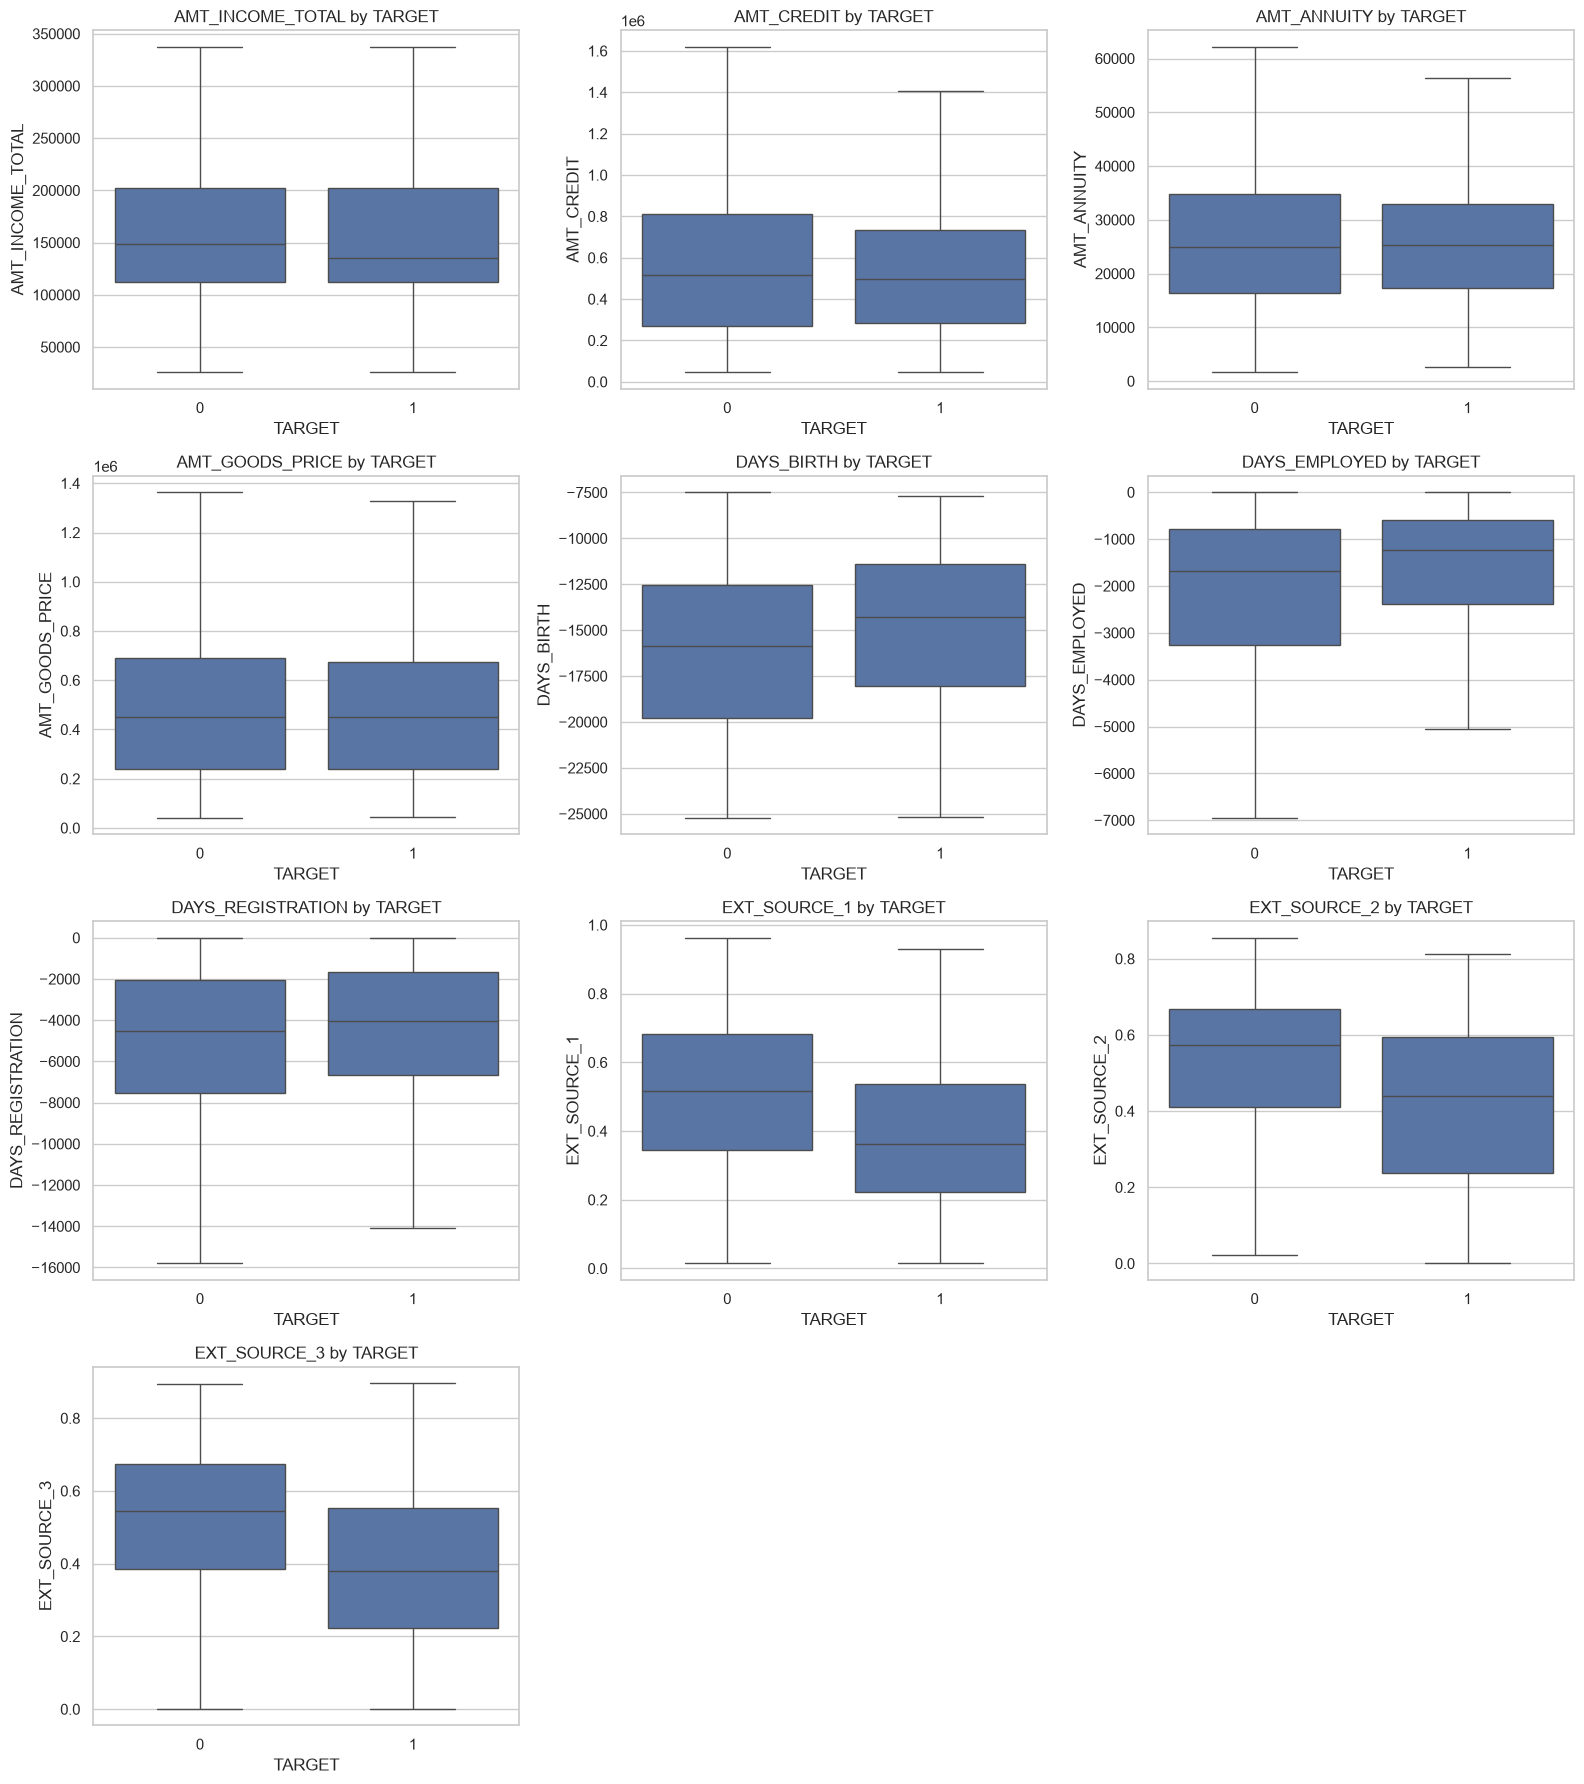

In [386]:
boxplot_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "DAYS_REGISTRATION",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

plot_df = relationship_df.copy()

plot_df.loc[plot_df["DAYS_EMPLOYED"] == 365243, "DAYS_EMPLOYED"] = None

n_cols = 3
n_rows = math.ceil(len(boxplot_features) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 4.5 * n_rows)
)

axes = axes.flatten()

for i, feature in enumerate(boxplot_features):
    sns.boxplot(
        data=plot_df,
        x="TARGET",
        y=feature,
        ax=axes[i],
        showfliers=False
    )
    axes[i].set_title(f"{feature} by TARGET")
    axes[i].set_xlabel("TARGET")
    axes[i].set_ylabel(feature)

# Delete empty plots
for i in range(len(boxplot_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.savefig(
    "../outputs/figures/numerical_features_vs_target.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Relación entre features categóricas y feature TARGET

In [387]:
categorical_binary_features = data_types.loc[
    data_types["Analytical Type"].isin([
        "Categorical",
        "Binary / Flag",
        "Ordinal"
    ]),
    "Feature"
].tolist()

categorical_relationship_df = train_df[categorical_binary_features + ["TARGET"]]
categorical_relationship_df

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,FLAG_MOBIL,...,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,TARGET
0,Cash loans,M,N,Y,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,1,...,0,0,0,0,0,0,0,0,0,1
1,Cash loans,F,N,N,Family,State servant,Higher education,Married,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0
2,Revolving loans,M,Y,Y,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0
3,Cash loans,F,N,Y,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0
4,Cash loans,M,N,Y,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,Cash loans,M,N,N,Unaccompanied,Working,Secondary / secondary special,Separated,With parents,1,...,0,0,0,0,0,0,0,0,0,0
307507,Cash loans,F,N,Y,Unaccompanied,Pensioner,Secondary / secondary special,Widow,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0
307508,Cash loans,F,N,Y,Unaccompanied,Working,Higher education,Separated,House / apartment,1,...,0,0,0,0,0,0,0,0,0,0
307509,Cash loans,F,N,Y,Unaccompanied,Commercial associate,Secondary / secondary special,Married,House / apartment,1,...,0,0,0,0,0,0,0,0,0,1


In [388]:
categorical_target_results = []
overall_target_rate = train_df["TARGET"].mean()

for feature in categorical_binary_features:
    summary = (
        categorical_relationship_df
        .groupby(feature, dropna=False)["TARGET"]
        .agg(
            Count="count",
            Target_1_Count="sum",
            Target_Rate="mean"
        )
        .reset_index()
    )

    summary.insert(0, "Feature", feature)
    summary = summary.rename(columns={feature: "Category"})
    summary["Dataset_Percentage"] = summary["Count"] / len(train_df) * 100
    summary["Target_Rate"] = summary["Target_Rate"] * 100
    categorical_target_results.append(summary)

categorical_target_summary = pd.concat(
    categorical_target_results,
    ignore_index=True
)
categorical_target_summary

,Feature,Category,Count,Target_1_Count,Target_Rate,Dataset_Percentage
0,NAME_CONTRACT_TYPE,Cash loans,278232,23221,8.345913,90.478715
1,NAME_CONTRACT_TYPE,Revolving loans,29279,1604,5.478329,9.521285
2,CODE_GENDER,F,202448,14170,6.999328,65.834393
3,CODE_GENDER,M,105059,10655,10.141920,34.164306
4,CODE_GENDER,XNA,4,0,0.000000,0.001301
...,...,...,...,...,...,...
211,FLAG_DOCUMENT_19,1,183,12,6.557377,0.059510
212,FLAG_DOCUMENT_20,0,307355,24812,8.072750,99.949270
213,FLAG_DOCUMENT_20,1,156,13,8.333333,0.050730
214,FLAG_DOCUMENT_21,0,307408,24811,8.071033,99.966505


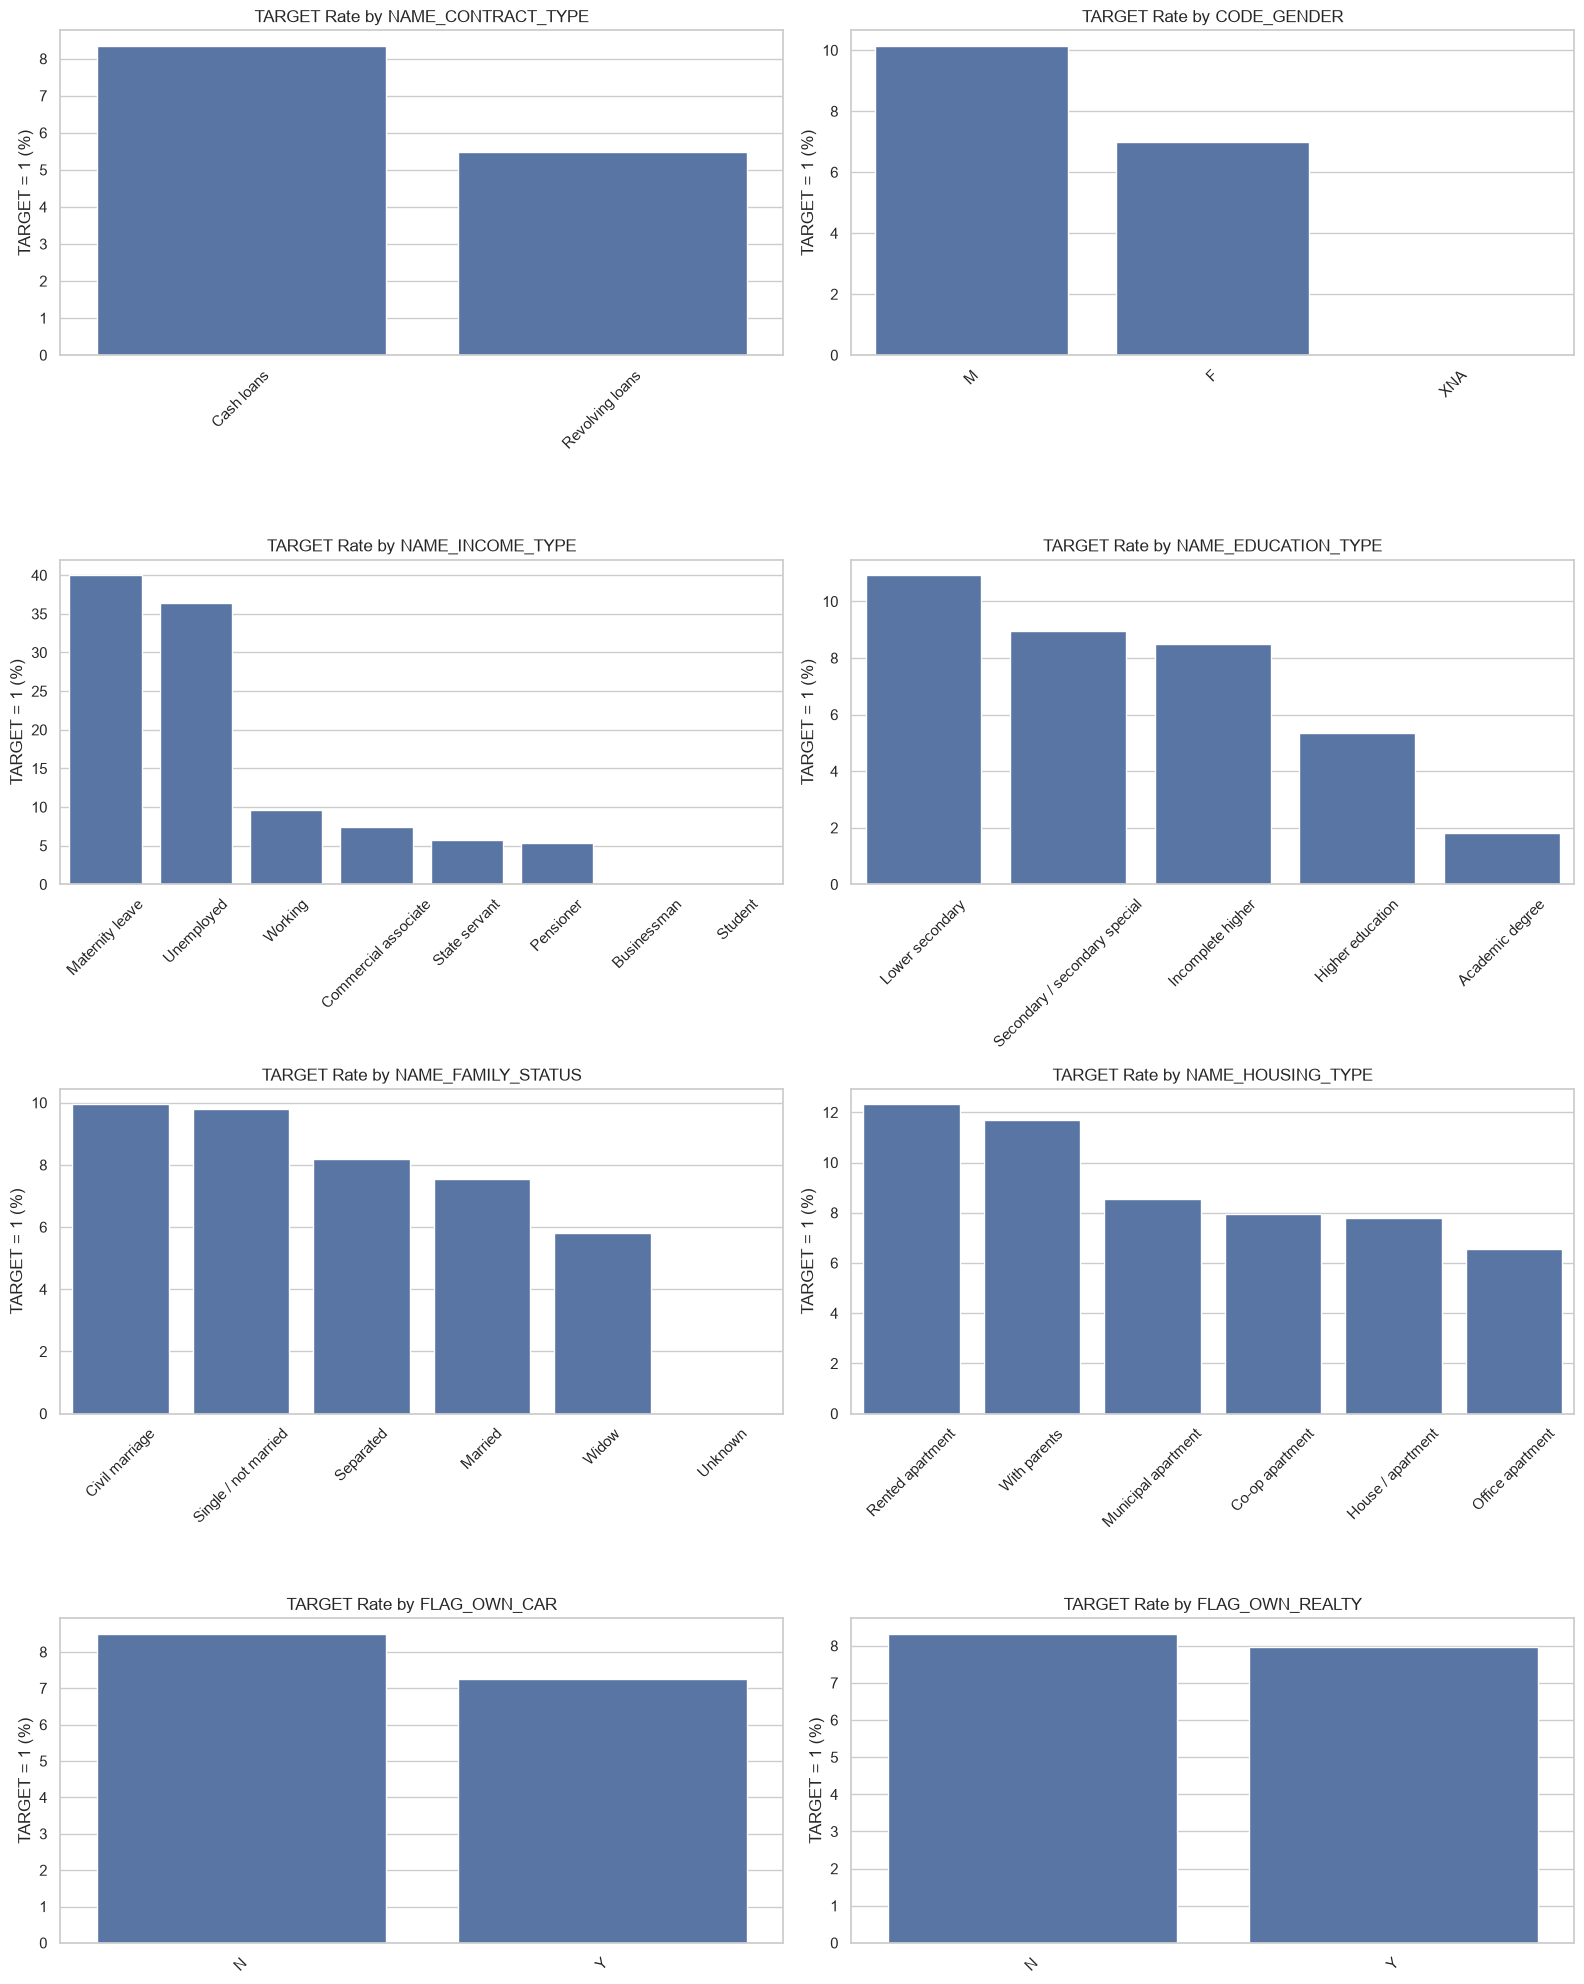

In [389]:
categorical_plot_features = [
    "NAME_CONTRACT_TYPE",
    "CODE_GENDER",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY"
]

n_cols = 2
n_rows = math.ceil(len(categorical_plot_features) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 5 * n_rows)
)

axes = axes.flatten()

for i, feature in enumerate(categorical_plot_features):

    feature_summary = categorical_target_summary[categorical_target_summary["Feature"] == feature].copy()
    feature_summary = feature_summary.sort_values("Target_Rate", ascending=False)
    sns.barplot(
        data=feature_summary,
        x="Category",
        y="Target_Rate",
        ax=axes[i]
    )

    axes[i].set_title(f"TARGET Rate by {feature}")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("TARGET = 1 (%)")

    axes[i].tick_params(axis="x", rotation=45)

for i in range(len(categorical_plot_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.savefig(
    "../outputs/figures/categorical_features_vs_target.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 13. CORRELATION ANALYSIS

In [390]:
numerical_features = data_types.loc[
    data_types["Analytical Type"].isin([
        "Numerical Continuous",
        "Numerical Count",
        "Temporal / Days",
        "External Score"
    ]),
    "Feature"
].tolist()

numerical_df = train_df[numerical_features + ["TARGET"]]
numerical_df

,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,...,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,202500.0,406597.5,24700.5,351000.0,0.018801,-9461,-637,-3648.0,-2120,...,2.0,2.0,-1134.0,0.0,0.0,0.0,0.0,0.0,1.0,1
1,0,270000.0,1293502.5,35698.5,1129500.0,0.003541,-16765,-1188,-1186.0,-291,...,1.0,0.0,-828.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,0,67500.0,135000.0,6750.0,135000.0,0.010032,-19046,-225,-4260.0,-2531,...,0.0,0.0,-815.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,0,135000.0,312682.5,29686.5,297000.0,0.008019,-19005,-3039,-9833.0,-2437,...,2.0,0.0,-617.0,NaN,NaN,NaN,NaN,NaN,NaN,0
4,0,121500.0,513000.0,21865.5,513000.0,0.028663,-19932,-3038,-4311.0,-3458,...,0.0,0.0,-1106.0,0.0,0.0,0.0,0.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,0,157500.0,254700.0,27558.0,225000.0,0.032561,-9327,-236,-8456.0,-1982,...,0.0,0.0,-273.0,NaN,NaN,NaN,NaN,NaN,NaN,0
307507,0,72000.0,269550.0,12001.5,225000.0,0.025164,-20775,365243,-4388.0,-4090,...,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0
307508,0,153000.0,677664.0,29979.0,585000.0,0.005002,-14966,-7921,-6737.0,-5150,...,6.0,0.0,-1909.0,1.0,0.0,0.0,1.0,0.0,1.0,0
307509,0,171000.0,370107.0,20205.0,319500.0,0.005313,-11961,-4786,-2562.0,-931,...,0.0,0.0,-322.0,0.0,0.0,0.0,0.0,0.0,0.0,1


In [391]:
#Calcular la correlación de Pearson para las features
correlation_features_df = numerical_df.corr(method="pearson")
correlation_features_df

,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,...,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
CNT_CHILDREN,1.000000,0.012882,0.002145,0.021374,-0.001827,-0.025573,0.330938,-0.239818,0.183395,-0.028019,...,0.015232,-0.001861,-0.005865,-0.000410,-0.000366,-0.002436,-0.010808,-0.007836,-0.041550,0.019187
AMT_INCOME_TOTAL,0.012882,1.000000,0.156870,0.191657,0.159610,0.074796,0.027261,-0.064223,0.027805,0.008506,...,-0.013015,-0.013135,-0.018585,0.000709,0.002944,0.002387,0.024700,0.004859,0.011690,-0.003982
AMT_CREDIT,0.002145,0.156870,1.000000,0.770138,0.986968,0.099738,-0.055436,-0.066838,0.009621,-0.006575,...,0.000239,-0.023767,-0.073701,-0.003906,0.004238,-0.001275,0.054451,0.015925,-0.048448,-0.030369
AMT_ANNUITY,0.021374,0.191657,0.770138,1.000000,0.775109,0.118429,0.009445,-0.104332,0.038514,0.011268,...,-0.011731,-0.024001,-0.063747,0.003861,0.002185,0.013881,0.039148,0.010124,-0.011320,-0.012817
AMT_GOODS_PRICE,-0.001827,0.159610,0.986968,0.775109,1.000000,0.103520,-0.053442,-0.064842,0.011565,-0.009267,...,0.000347,-0.024506,-0.076313,-0.003237,0.004677,-0.001007,0.056422,0.016432,-0.050998,-0.039645
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_WEEK,-0.002436,0.002387,-0.001275,0.013881,-0.001007,-0.002149,-0.001336,0.003072,-0.001069,-0.001249,...,0.000197,-0.002536,-0.003495,0.004706,0.217412,1.000000,-0.014096,-0.015115,0.018917,0.000788
AMT_REQ_CREDIT_BUREAU_MON,-0.010808,0.024700,0.054451,0.039148,0.056422,0.078607,0.001372,-0.034457,-0.011353,-0.009660,...,0.001639,-0.001462,-0.041244,-0.000018,-0.005258,-0.014096,1.000000,-0.007789,-0.004975,-0.012462
AMT_REQ_CREDIT_BUREAU_QRT,-0.007836,0.004859,0.015925,0.010124,0.016432,-0.001279,-0.011799,0.015345,-0.001308,-0.006200,...,0.003932,-0.000291,-0.001451,-0.002716,-0.004416,-0.015115,-0.007789,1.000000,0.076208,-0.002022
AMT_REQ_CREDIT_BUREAU_YEAR,-0.041550,0.011690,-0.048448,-0.011320,-0.050998,0.001003,-0.071983,0.049988,-0.024805,-0.035099,...,0.032957,0.017190,-0.112725,-0.004597,-0.003355,0.018917,-0.004975,0.076208,1.000000,0.019930


In [392]:
# Keep only the upper triangle to avoid duplicates
upper_triangle = correlation_features_df.where(
    np.triu(
        np.ones(correlation_features_df.shape),
        k=1
    ).astype(bool)
)

# Convert correlation matrix into a list of feature pairs
correlation_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

correlation_pairs

,Feature 1,Feature 2,Correlation
0,CNT_CHILDREN,CNT_CHILDREN,NaN
1,CNT_CHILDREN,AMT_INCOME_TOTAL,0.012882
2,CNT_CHILDREN,AMT_CREDIT,0.002145
3,CNT_CHILDREN,AMT_ANNUITY,0.021374
4,CNT_CHILDREN,AMT_GOODS_PRICE,-0.001827
...,...,...,...
5036,TARGET,AMT_REQ_CREDIT_BUREAU_WEEK,NaN
5037,TARGET,AMT_REQ_CREDIT_BUREAU_MON,NaN
5038,TARGET,AMT_REQ_CREDIT_BUREAU_QRT,NaN
5039,TARGET,AMT_REQ_CREDIT_BUREAU_YEAR,NaN


In [393]:
#Ranking Strongest positive/negative relationships
highest_positive_correlation = correlation_pairs.sort_values("Correlation", ascending=False).head(10)
highest_negative_correlation = correlation_pairs.sort_values("Correlation", ascending=True).head(10)
print(highest_positive_correlation)
print(highest_negative_correlation)

                     Feature 1                 Feature 2  Correlation
1396           YEARS_BUILD_AVG          YEARS_BUILD_MEDI     0.998495
4250  OBS_30_CNT_SOCIAL_CIRCLE  OBS_60_CNT_SOCIAL_CIRCLE     0.998490
1756             FLOORSMIN_AVG            FLOORSMIN_MEDI     0.997241
1684             FLOORSMAX_AVG            FLOORSMAX_MEDI     0.997034
1612             ENTRANCES_AVG            ENTRANCES_MEDI     0.996886
1540             ELEVATORS_AVG            ELEVATORS_MEDI     0.996099
1468            COMMONAREA_AVG           COMMONAREA_MEDI     0.995978
1972            LIVINGAREA_AVG           LIVINGAREA_MEDI     0.995596
1180            APARTMENTS_AVG           APARTMENTS_MEDI     0.995081
1252          BASEMENTAREA_AVG         BASEMENTAREA_MEDI     0.994317
              Feature 1               Feature 2  Correlation
433          DAYS_BIRTH           DAYS_EMPLOYED    -0.615864
439          DAYS_BIRTH            EXT_SOURCE_1    -0.600610
506       DAYS_EMPLOYED         DAYS_ID_PUBLISH

In [394]:
highest_correlations = pd.concat([highest_negative_correlation, highest_positive_correlation], ignore_index=True)
highest_correlations.to_csv("../outputs/data_understanding/high_correlations.csv")
highest_correlations

,Feature 1,Feature 2,Correlation
0,DAYS_BIRTH,DAYS_EMPLOYED,-0.615864
1,DAYS_BIRTH,EXT_SOURCE_1,-0.600610
2,DAYS_EMPLOYED,DAYS_ID_PUBLISH,-0.272378
3,CNT_CHILDREN,DAYS_EMPLOYED,-0.239818
4,DAYS_EMPLOYED,CNT_FAM_MEMBERS,-0.233549
5,DAYS_EMPLOYED,DAYS_REGISTRATION,-0.210242
6,DAYS_BIRTH,EXT_SOURCE_3,-0.205478
7,EXT_SOURCE_2,DAYS_LAST_PHONE_CHANGE,-0.195764
8,DAYS_REGISTRATION,EXT_SOURCE_1,-0.181095
9,EXT_SOURCE_3,TARGET,-0.178919


In [395]:
#Extraer las variables comunes del df de correlacion
heatmap_features = pd.unique(highest_correlations[["Feature 1", "Feature 2"]].values.ravel()).tolist()
print(f"Number of unique features: {len(heatmap_features)}")

Number of unique features: 31


In [396]:
heatmap_correlation = numerical_df[heatmap_features].corr(method="pearson")

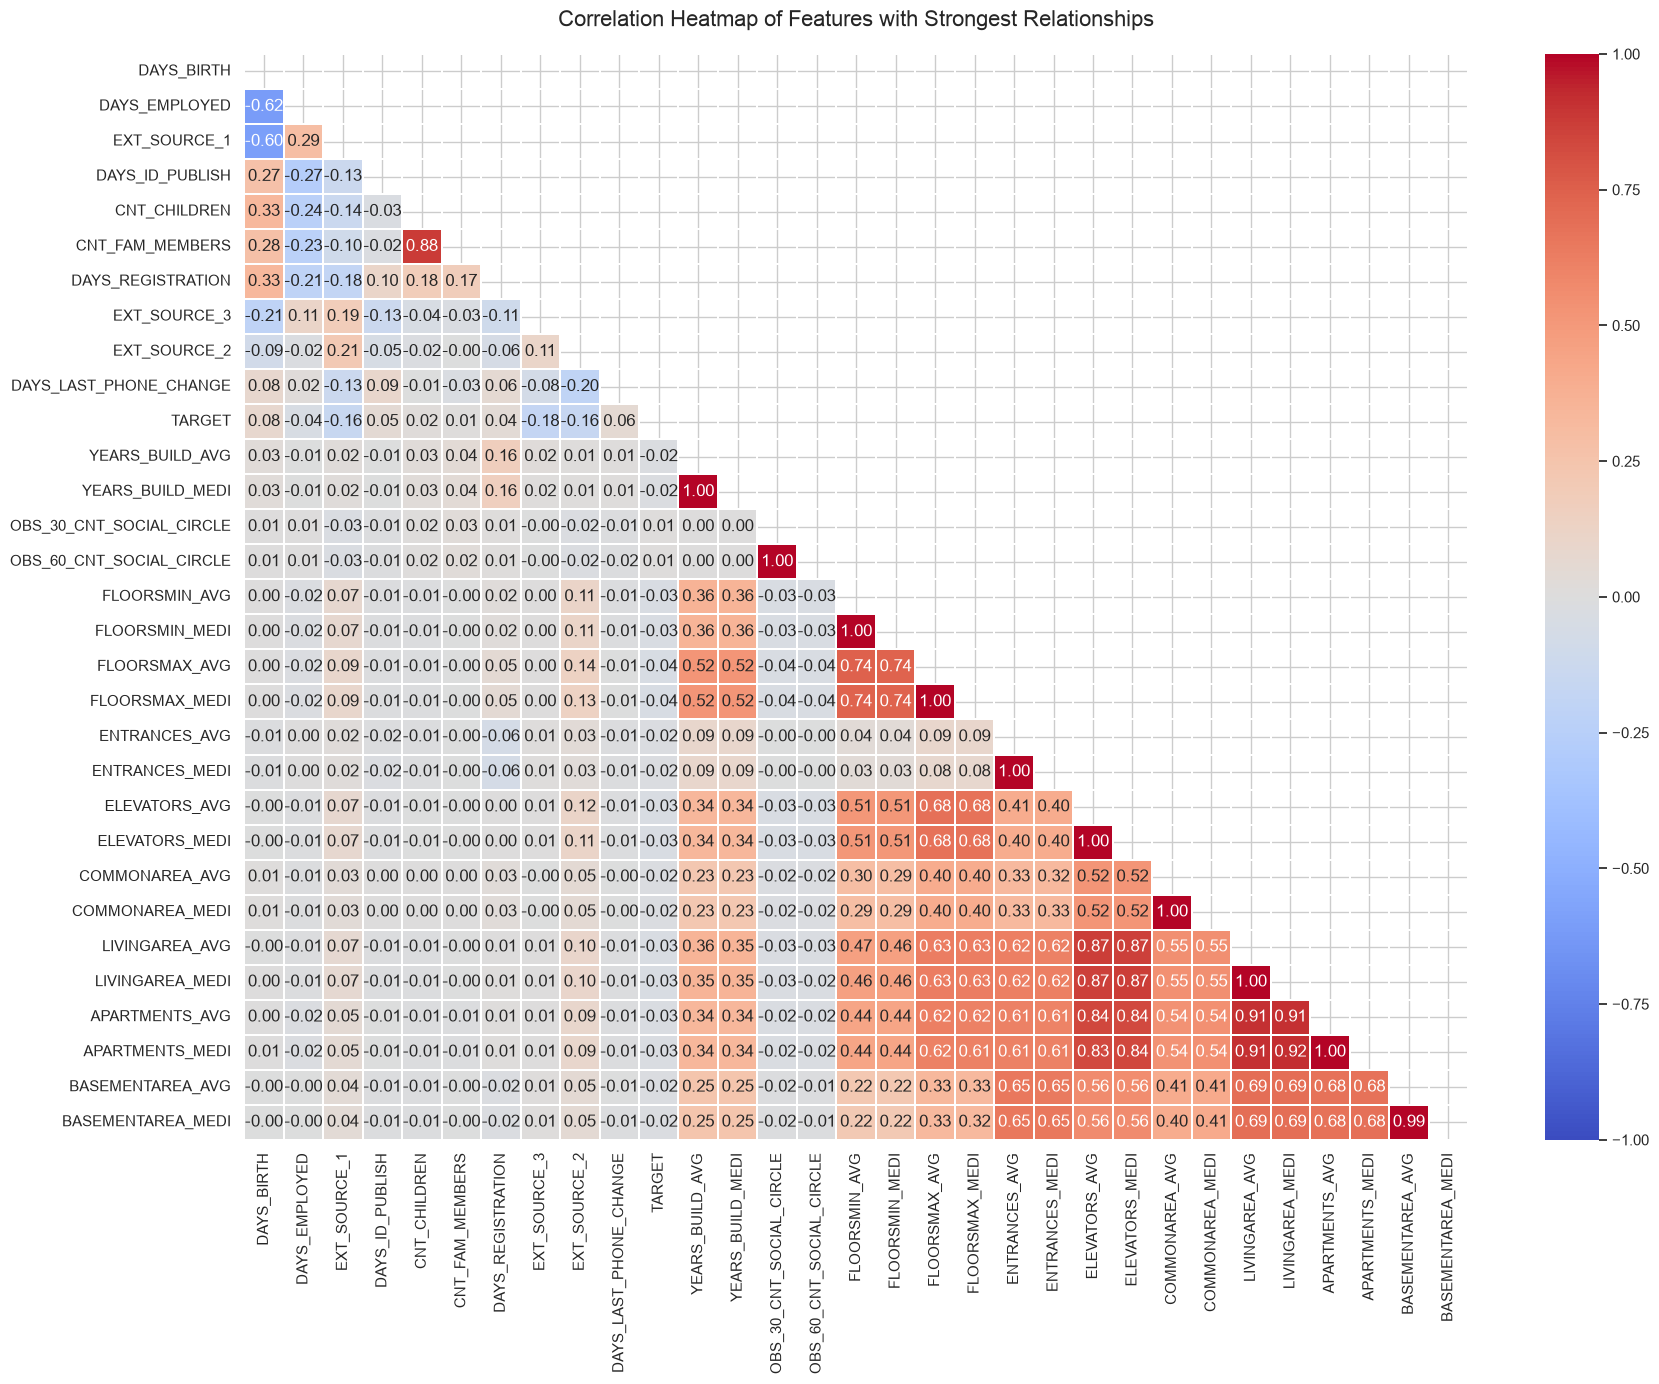

In [397]:
mask = np.triu(np.ones_like(heatmap_correlation, dtype=bool))
plt.figure(figsize=(18, 14))
sns.heatmap(
    heatmap_correlation,
    mask=mask,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3,
    annot=True,
    fmt=".2f"
)
plt.title(
    "Correlation Heatmap of Features with Strongest Relationships",
    fontsize=16,
    pad=20
)
plt.tight_layout()
plt.savefig(
    "../outputs/figures/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 14. INITIAL FINDINGS

14.1 Key Dataset Findings

En el dataset de entrenamiento hemos encontrado principalmente las siguientes características:

1. Dataset de gran forma, 307511 filas de registros y 122 columnas distintas.
2. Estas columnas del dataset contienen una mezcla de variables numéricas, categóricas, binarias, ordinales  y temporales.
3. La feature objetivo, TARGET, se encuentra claramente desbalanceada. Siendo una feature categórica con posibles valores 0 y 1, encontramos 282686 registros con el valor de 0 en la feature de TARGET y 24825 con el valor de 1 en la feature de TARGET.
4. Encontramos la presencia de valores nulos sobre todo en features categóricas como COMMONAREA_AVG y COMMONAREA_MEDI llegando a un 69.87% de los datos nulos, encontrándose entre un 47.40% y 69.87% las features con mayores valores nulos de los datos.
5. Estudiamos la redundancia entre features relacionadas como vivienda/inmuebles y sus variantes AVG, MEDI, MODE.

14.2 Data Quality and Modelling Implications

A continuación planteamos la relación entre cada sección analizada y los resultados obtenidos con sus implicaciones en los procesos posteriores para la Data Preparation y Modelling

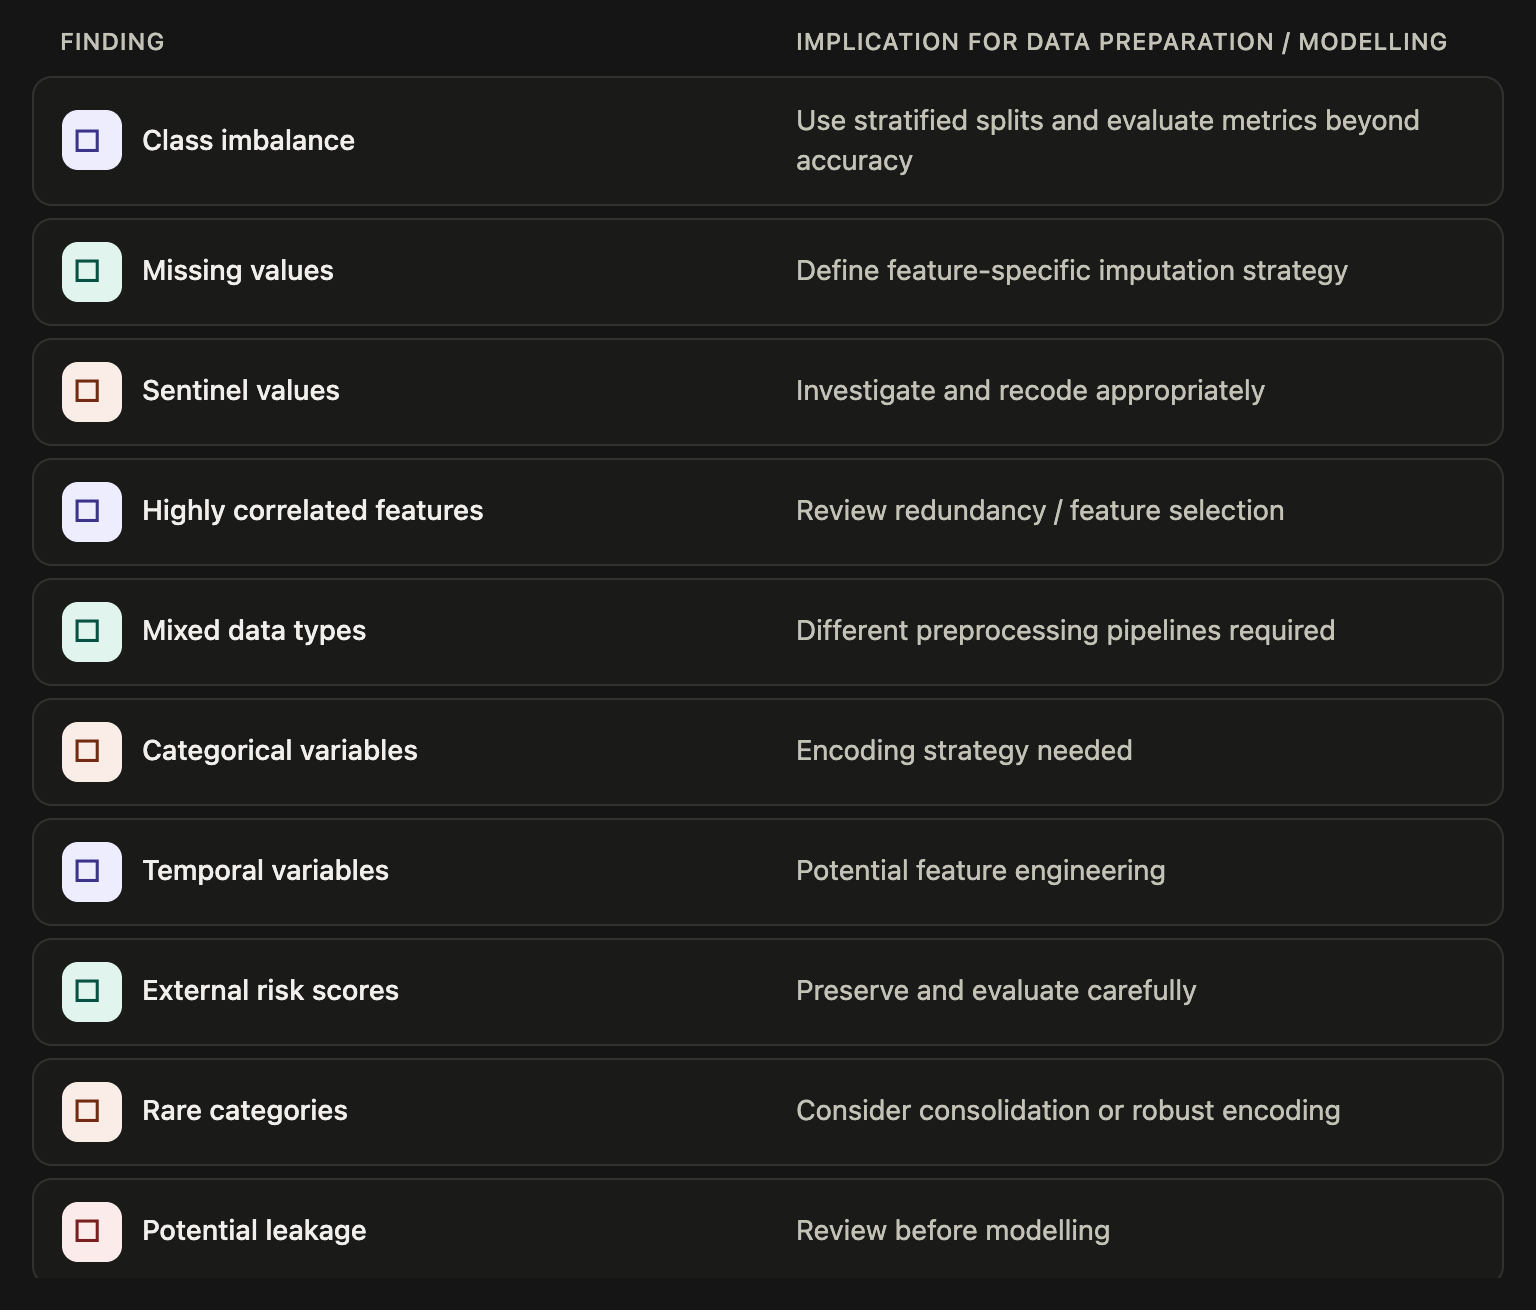